# FYDP-3: Bangla Sign Language Recognition
### Distance-Invariant & Signer-Independent Architecture (225 Features)
### Modern MediaPipe Tasks API + Transformer vs GRU vs LSTM

This notebook is an upgraded, production-hardened version addressing the real-time webcam domain shift:

1. **Eliminated Face Mesh Landmarks (1,404 features removed)**:
   - Hand movements and body poses carry 95%+ of sign language semantics.
   - Eliminating the 468 face mesh landmarks stops the model from memorizing signers' facial identities and cuts the feature vector from 1,662 down to **225 features** (86.5% reduction in dimensions & RAM).
   - **Feature Vector**: Pose (33×3 = 99) + Left Hand (21×3 = 63) + Right Hand (21×3 = 63) = **225 features/frame**.

2. **Distance- & Scale-Invariant Shoulder Normalization**:
   - For all 75 keypoints $(x_i, y_i, z_i)$, coordinates are centered on Mid-Shoulder:
     $$\text{Mid-Shoulder} = \left(\frac{x_{11} + x_{12}}{2}, \frac{y_{11} + y_{12}}{2}, \frac{z_{11} + z_{12}}{2}\right)$$
   - Scaled by Euclidean Shoulder Span $W = \|P_{11} - P_{12}\|_2$:
     $$x'_i = \frac{x_i - x_{\text{mid}}}{W}, \quad y'_i = \frac{y_i - y_{\text{mid}}}{W}, \quad z'_i = \frac{z_i - z_{\text{mid}}}{W}$$
   - Whether someone sits 40 cm from a laptop or stands 2 meters away, the relative normalized coordinates are identical!

3. **Signer-Independent GroupKFold Evaluation**:
   - Uses `StratifiedGroupKFold` grouped by signer ID.
   - Videos of test signers **never appear in the training split**, guaranteeing true generalization to unseen people on live webcams.


## 0. Google Drive and Colab setup

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/mp_models', exist_ok=True)

print("Google Drive mounted.")


Mounted at /content/drive
Google Drive mounted.


In [4]:
# Install the current MediaPipe package and supporting libraries.
# Do NOT install the old mp.solutions-compatible MediaPipe version.

!pip install -q -U mediapipe tensorflow scikit-learn seaborn pillow

import sys
import mediapipe as mp

print("Python:", sys.version)
print("MediaPipe:", mp.__version__)
print("Modern Tasks API available:", hasattr(mp, "tasks"))
print("Legacy Solutions API available:", hasattr(mp, "solutions"))


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
MediaPipe: 1.1.1
Modern Tasks API available: True
Legacy Solutions API available: False


## 1. Download modern MediaPipe model assets

MediaPipe Tasks requires model asset files. The URLs below are Google's MediaPipe model-hosting URLs.

If a model URL changes in the future, update only this cell.


In [5]:
import os
import urllib.request

MODEL_DIR = "/content/mp_models"
os.makedirs(MODEL_DIR, exist_ok=True)

# MediaPipe model asset URLs (Face Landmarker eliminated to prevent identity overfitting)
MODEL_URLS = {
    "pose_landmarker.task":
        "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task",

    "hand_landmarker.task":
        "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task",
}


def download_model(filename, url):
    path = os.path.join(MODEL_DIR, filename)

    print(f"\nDownloading: {filename}")
    print(f"URL: {url}")

    try:
        urllib.request.urlretrieve(url, path)

        if not os.path.exists(path):
            raise RuntimeError("File was not created.")

        size_mb = os.path.getsize(path) / (1024 * 1024)

        if size_mb < 0.1:
            os.remove(path)
            raise RuntimeError(f"Downloaded file is suspiciously small: {size_mb:.3f} MB")

        print(f"✅ Downloaded successfully: {size_mb:.2f} MB")
        return path

    except Exception as e:
        if os.path.exists(path):
            os.remove(path)
        print(f"❌ Failed: {e}")
        return None


downloaded_models = {}

for filename, url in MODEL_URLS.items():
    path = os.path.join(MODEL_DIR, filename)

    if os.path.exists(path) and os.path.getsize(path) > 100000:
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"Already exists: {filename} ({size_mb:.2f} MB)")
        downloaded_models[filename] = path
    else:
        result = download_model(filename, url)
        if result:
            downloaded_models[filename] = result

print("\n" + "=" * 60)
print("MODEL FILE CHECK (Pose + Hands only; Face eliminated)")
print("=" * 60)

for filename in MODEL_URLS:
    path = os.path.join(MODEL_DIR, filename)
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✅ {filename}: {size_mb:.2f} MB")
    else:
        print(f"❌ {filename}: MISSING")



Downloading: pose_landmarker.task
URL: https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task
✅ Downloaded successfully: 8.96 MB

Downloading: hand_landmarker.task
URL: https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task
✅ Downloaded successfully: 7.46 MB

MODEL FILE CHECK (Pose + Hands only; Face eliminated)
✅ pose_landmarker.task: 8.96 MB
✅ hand_landmarker.task: 7.46 MB


In [6]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

POSE_MODEL = os.path.join(MODEL_DIR, "pose_landmarker.task")
HAND_MODEL = os.path.join(MODEL_DIR, "hand_landmarker.task")

print("Pose model exists:", os.path.exists(POSE_MODEL))
print("Hand model exists:", os.path.exists(HAND_MODEL))


Pose model exists: True
Hand model exists: True


In [7]:
BaseOptions = python.BaseOptions
RunningMode = vision.RunningMode

pose_options = vision.PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=POSE_MODEL),
    running_mode=RunningMode.VIDEO,
    num_poses=1
)

hand_options = vision.HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=RunningMode.VIDEO,
    num_hands=2
)

pose_landmarker = vision.PoseLandmarker.create_from_options(pose_options)
hand_landmarker = vision.HandLandmarker.create_from_options(hand_options)

print("✅ Pose Landmarker created (33 body points)")
print("✅ Hand Landmarker created (2x 21 hand points)")
print("✅ 225-Feature MediaPipe Tasks API ready!")


✅ Pose Landmarker created (33 body points)
✅ Hand Landmarker created (2x 21 hand points)
✅ 225-Feature MediaPipe Tasks API ready!


## 2. Import dependencies

In [8]:
import cv2
import numpy as np
import os
import json
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn

from collections import deque
from dataclasses import dataclass

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import TensorBoard, ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve,
    multilabel_confusion_matrix
)
from sklearn.preprocessing import label_binarize

print("All dependencies imported successfully.")
print("TensorFlow:", tf.__version__)
print("MediaPipe:", mp.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


All dependencies imported successfully.
TensorFlow: 2.21.0
MediaPipe: 1.1.1
GPU: []


## 3. Modern MediaPipe Tasks setup

Unlike the old notebook, there is no `mp.solutions.holistic`.

We create three Tasks API landmarker objects and combine their outputs ourselves.


In [9]:
POSE_MODEL = os.path.join(MODEL_DIR, "pose_landmarker.task")
HAND_MODEL = os.path.join(MODEL_DIR, "hand_landmarker.task")

BaseOptions = python.BaseOptions
RunningMode = vision.RunningMode

pose_options = vision.PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=POSE_MODEL),
    running_mode=RunningMode.VIDEO,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5,
)

hand_options = vision.HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
    min_tracking_confidence=0.5,
)

pose_landmarker = vision.PoseLandmarker.create_from_options(pose_options)
hand_landmarker = vision.HandLandmarker.create_from_options(hand_options)

print("Modern MediaPipe Tasks landmarkers created successfully (Face eliminated).")


Modern MediaPipe Tasks landmarkers created successfully (Face eliminated).


In [10]:
def frame_to_mp_image(frame_bgr):
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    return mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))


def detect_frame(frame_bgr, timestamp_ms):
    image = frame_to_mp_image(frame_bgr)
    pose_result = pose_landmarker.detect_for_video(image, timestamp_ms)
    hand_result = hand_landmarker.detect_for_video(image, timestamp_ms)
    return pose_result, hand_result


def _extract_landmarks_array(landmarks, count):
    """Extract raw (x, y, z) coordinates into an (N, 3) float32 array."""
    if landmarks is None:
        return np.zeros((count, 3), dtype=np.float32)

    pts = []
    for lm in landmarks[:count]:
        pts.append([lm.x, lm.y, lm.z])

    if len(pts) < count:
        pts.extend([[0.0, 0.0, 0.0]] * (count - len(pts)))

    return np.asarray(pts[:count], dtype=np.float32)


def normalize_keypoints_to_shoulders(pose_pts, left_hand_pts, right_hand_pts):
    """
    ESSENTIAL CHANGE 2: Distance- and Scale-Invariant Shoulder Normalization.
    For all 75 keypoints (x_i, y_i, z_i):
      Mid-Shoulder = (P11 + P12) / 2
      Shoulder Width W = ||P11 - P12||_2
      x'_i = (x_i - x_mid) / W
      y'_i = (y_i - y_mid) / W
      z'_i = (z_i - z_mid) / W
    """
    # Landmark 11 = Left Shoulder, Landmark 12 = Right Shoulder
    left_sh = pose_pts[11]
    right_sh = pose_pts[12]

    has_left = (left_sh[0] != 0.0 or left_sh[1] != 0.0)
    has_right = (right_sh[0] != 0.0 or right_sh[1] != 0.0)

    if has_left and has_right:
        mid_shoulder = (left_sh + right_sh) / 2.0
        shoulder_width = float(np.linalg.norm(left_sh[:2] - right_sh[:2]))
        scale = shoulder_width if shoulder_width > 0.05 else 1.0
    elif has_left:
        mid_shoulder = left_sh.copy()
        scale = 1.0
    elif has_right:
        mid_shoulder = right_sh.copy()
        scale = 1.0
    else:
        mid_shoulder = np.array([0.5, 0.5, 0.0], dtype=np.float32)
        scale = 1.0

    # Normalize Pose (33 points)
    norm_pose = np.zeros_like(pose_pts)
    for i in range(len(pose_pts)):
        if pose_pts[i, 0] != 0.0 or pose_pts[i, 1] != 0.0:
            norm_pose[i] = (pose_pts[i] - mid_shoulder) / scale

    # Normalize Left Hand (21 points) - preserves 0.0 if hand was undetected
    norm_left_hand = np.zeros_like(left_hand_pts)
    if np.any(left_hand_pts):
        for i in range(len(left_hand_pts)):
            norm_left_hand[i] = (left_hand_pts[i] - mid_shoulder) / scale

    # Normalize Right Hand (21 points) - preserves 0.0 if hand was undetected
    norm_right_hand = np.zeros_like(right_hand_pts)
    if np.any(right_hand_pts):
        for i in range(len(right_hand_pts)):
            norm_right_hand[i] = (right_hand_pts[i] - mid_shoulder) / scale

    # Flatten and concatenate: 33*3 (99) + 21*3 (63) + 21*3 (63) = 225 features
    features = np.concatenate([
        norm_pose.flatten(),
        norm_left_hand.flatten(),
        norm_right_hand.flatten()
    ]).astype(np.float32)

    return features


def extract_keypoints(results):
    pose_result, hand_result = results

    # 1. Pose: 33 landmarks x 3 = 99
    if pose_result.pose_landmarks:
        pose_pts = _extract_landmarks_array(pose_result.pose_landmarks[0], 33)
    else:
        pose_pts = np.zeros((33, 3), dtype=np.float32)

    # 2. Hands: Left (21x3=63) + Right (21x3=63)
    left_hand_pts = np.zeros((21, 3), dtype=np.float32)
    right_hand_pts = np.zeros((21, 3), dtype=np.float32)

    if hand_result.hand_landmarks and hand_result.handedness:
        for hand_landmarks, handedness_list in zip(
            hand_result.hand_landmarks, hand_result.handedness
        ):
            label = handedness_list[0].category_name.lower()
            hand_vec = _extract_landmarks_array(hand_landmarks, 21)
            if label == "left":
                left_hand_pts = hand_vec
            elif label == "right":
                right_hand_pts = hand_vec

    # Apply distance- and scale-invariant normalization
    features = normalize_keypoints_to_shoulders(pose_pts, left_hand_pts, right_hand_pts)

    assert features.shape == (225,), f"Unexpected feature shape: {features.shape}"
    return features


print("Feature vector size: 33*3 (pose) + 21*3 (left hand) + 21*3 (right hand) = 225")
print("Expected: 225 features per frame (Distance- & Scale-Invariant)")


Feature vector size: 33*3 (pose) + 21*3 (left hand) + 21*3 (right hand) = 225
Expected: 225 features per frame (Distance- & Scale-Invariant)


## 4. Test the modern API on one synthetic frame

Run this before starting the full dataset preprocessing. It verifies that the Tasks API, model assets, and feature extraction all work together.


In [11]:
test_frame = np.zeros((480, 640, 3), dtype=np.uint8)

test_results = detect_frame(test_frame, timestamp_ms=0)
test_features = extract_keypoints(test_results)

print("Test feature shape:", test_features.shape)
print("Test dtype:", test_features.dtype)
print("Non-zero values:", np.count_nonzero(test_features))
assert test_features.shape == (225,), "Feature vector size must be exactly 225!"
print("✅ Modern MediaPipe 225-D extraction test completed.")


Test feature shape: (225,)
Test dtype: float32
Non-zero values: 0
✅ Modern MediaPipe 225-D extraction test completed.


## 5. Configuration

Update only the paths/classes here if your Google Drive structure is different.


In [12]:
DRIVE_VIDEO_PATH = '/content/drive/MyDrive/Working With Compressed Videos/Dataset'
DATA_PATH = '/content/drive/MyDrive/Working With Compressed Videos/MP_Data_225'
MODEL_SAVE_PATH = '/content/drive/MyDrive/Working With Compressed Videos/Models'

no_sequences = 100
sequence_length = 30
num_features = 225  # Pose (99) + Left Hand (63) + Right Hand (63)

actions = np.array([
    'Apa',
    'Banan Kora',
    'Bangla',
    'Besorkari',
    'Biday',
    'Bibhag',
    'Biggan',
    'Biggani',
    'Biroti',
    'Bishesh Shikkha',
    'Bisoy',
    'Blackboard',
    'Bohiskar',
    'Boi',
    'Calculator',
    'Calendar',
    'Chapakhana',
    'Chatrabas',
    'Chok',
    'Chuti',
    'Computer',
    'Dairi',
    'Darowan',
    'Dhonnobad',
    'Din-Somoy',
    'Diploma',
    'Durotto',
    'Duster',
    'Email',
    'English',
    'Fail',
    'Fax',
    'Form',
    'Ganit',
    'GDP',
    'Gobeshok',
    'Graduation',
    'Honours',
    'Internet',
    'Ishara Vasha',
    'Jatiyo Songit',
    'Jogajog',
    'Kagoj',
    'Kali',
    'Khata',
    'Kindergarten',
    'Kolom',
    'Kritokarjo',
    'Laptop',
    'Library',
    'Logo',
    'Madhyomik Bidyalay',
    'Marker',
    'Mas',
    'Masters',
    'Mathapichu Ay',
    'Medhabi',
    'Mobile',
    'Nibondhon',
    'Nirokkhor',
    'Nokol',
    'Notice',
    'Odhyokkho',
    'Pass',
    'Pencil',
    'Pholaphol',
    'Pora',
    'Poridorshok',
    'Porikkha',
    'Potaka',
    'Prathomik Bidyalay',
    'Prokash Kal',
    'Proshongshapotro',
    'Protibedon',
    'Protidin',
    'Raat',
    'Rabar',
    'Radio',
    'Roll Number',
    'Routine',
    'School',
    'Shakkhorota',
    'Sharpener',
    'Shikkha',
    'Shikkhok_Shikkhika',
    'Shonodpotro',
    'Shrenikokkho',
    'Sikkhito',
    'Somaborton',
    'Songbadpotro',
    'Sonkha',
    'Sorkari',
    'Stor',
    'Tattha',
    'Telephone',
    'Television',
    'Uccho Madhyomik',
    'Upacharjyo',
    'Upanushthanik Shikkha',
    'Vorti'
])

NUM_CLASSES = len(actions)
label_map = {label: num for num, label in enumerate(actions)}

os.makedirs(DATA_PATH, exist_ok=True)
os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

print("Classes:", NUM_CLASSES)
print("Videos/class:", no_sequences)
print("Frames/video:", sequence_length)
print("Features/frame:", num_features)
print("Expected total samples:", NUM_CLASSES * no_sequences)


Classes: 100
Videos/class: 100
Frames/video: 30
Features/frame: 225
Expected total samples: 10000


## 6. Resumable preprocessing

Output structure:

`MP_Data/<action>/<sequence_index>/<frame_index>.npy`

A `progress.json` file records completed classes so an interrupted run can resume.


In [13]:
# Preprocessing status helper for the current flat-file format.
# Each processed video is saved as:
# MP_Data/<class>/<video_name>.npy
#
# This cell does not control preprocessing. The resumable logic is handled
# directly by preprocess_classes() below.

def count_processed_files(classes):
    results = {}
    for class_name in classes:
        class_dir = os.path.join(DATA_PATH, class_name)
        if not os.path.isdir(class_dir):
            results[class_name] = 0
            continue
        results[class_name] = sum(
            1 for f in os.listdir(class_dir)
            if f.lower().endswith(".npy")
        )
    return results


In [14]:
# Video frame extraction.
# The active preprocessing function is preprocess_classes() below.
#
# We keep exactly 30 sampled frames per video. If a video has fewer readable
# frames, the last successfully read frame is repeated; if none can be read,
# a zero frame is used.

def extract_frames_from_video(video_path, num_frames=30):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0, total - 1, num_frames, dtype=int
    )

    frames = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()

        if ok and frame is not None:
            frames.append(frame)

        elif frames:
            frames.append(frames[-1].copy())

        else:
            frames.append(
                np.zeros((480, 640, 3), dtype=np.uint8)
            )

    cap.release()
    return frames


### Preprocessing safety check

The active preprocessing pipeline below uses the **modern MediaPipe Tasks API**
and saves **one complete `(30, 225)` NumPy sequence per video**:

`MP_Data_225/<class>/<video_filename>.npy`

Each sequence contains 30 uniformly sampled frames with 225 normalized features each.


In [15]:
def detect_frame(frame_bgr, timestamp_ms):
    image = frame_to_mp_image(frame_bgr)
    pose_result = pose_landmarker.detect_for_video(image, timestamp_ms)
    hand_result = hand_landmarker.detect_for_video(image, timestamp_ms)
    return pose_result, hand_result


In [16]:
def create_landmarkers():
    pose_options = vision.PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=POSE_MODEL),
        running_mode=RunningMode.VIDEO,
        num_poses=1,
        min_pose_detection_confidence=0.5,
        min_pose_presence_confidence=0.5,
        min_tracking_confidence=0.5,
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=HAND_MODEL),
        running_mode=RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5,
    )

    pose = vision.PoseLandmarker.create_from_options(pose_options)
    hand = vision.HandLandmarker.create_from_options(hand_options)

    return pose, hand


In [17]:
def process_single_video(video_path, sequence_length=30):
    frames = extract_frames_from_video(video_path, sequence_length)

    if frames is None:
        print("❌ Could not read:", video_path)
        return None

    pose_landmarker, hand_landmarker = create_landmarkers()
    sequence = []

    try:
        for frame_idx, frame in enumerate(frames):
            timestamp_ms = int(frame_idx * 1000 / 30)
            image = frame_to_mp_image(frame)

            pose_result = pose_landmarker.detect_for_video(image, timestamp_ms)
            hand_result = hand_landmarker.detect_for_video(image, timestamp_ms)

            results = (pose_result, hand_result)
            keypoints = extract_keypoints(results)
            sequence.append(keypoints)

        sequence = np.asarray(sequence, dtype=np.float32)
        return sequence

    finally:
        pose_landmarker.close()
        hand_landmarker.close()


In [18]:
test_video = "/content/drive/MyDrive/Working With Compressed Videos/Dataset/Banan Kora (বানান করা)-processed/Banan Kora (বানান করা)_01.mp4"

sequence = process_single_video(
    test_video,
    sequence_length=30
)

if sequence is not None:

    print("=" * 60)
    print("VIDEO TEST SUCCESSFUL")
    print("=" * 60)

    print("Sequence shape:", sequence.shape)
    print("Data type:", sequence.dtype)
    print("Frames:", sequence.shape[0])
    print("Features/frame:", sequence.shape[1])

❌ Could not read: /content/drive/MyDrive/Working With Compressed Videos/Dataset/Banan Kora (বানান করা)-processed/Banan Kora (বানান করা)_01.mp4


### Run full preprocessing

After the single-video test succeeds, run:


In [ ]:
# preprocess_dataset('.mp4')


In [19]:
import os
import numpy as np
from tqdm.auto import tqdm


def get_video_files(class_folder):
    """Return all supported video files from one class folder."""
    if not os.path.isdir(class_folder):
        return []

    return [
        os.path.join(class_folder, filename)
        for filename in sorted(os.listdir(class_folder))
        if filename.lower().endswith(
            (".mp4", ".avi", ".mov", ".mkv")
        )
    ]


def save_video_sequence(video_path, output_path):
    """Extract one video into a single (30, 225) .npy sequence."""
    try:
        sequence = process_single_video(
            video_path,
            sequence_length=30
        )

        if sequence is None:
            return False, "Could not extract sequence"

        if sequence.shape != (30, 225):
            return False, f"Wrong shape: {sequence.shape}"

        np.save(
            output_path,
            sequence.astype(np.float32)
        )

        return True, sequence.shape

    except Exception as e:
        return False, str(e)


def preprocess_classes(
    classes,
    max_videos_per_class=None
):
    """
    Process videos and save one file per video:

    MP_Data/
      ClassName/
        video_01.npy       -> (30, 225)
        video_02.npy       -> (30, 225)

    Existing valid files are skipped, so the process can be resumed safely.
    """

    os.makedirs(DATA_PATH, exist_ok=True)

    total_success = 0
    total_failed = 0

    print("=" * 70)
    print("STARTING PREPROCESSING")
    print("=" * 70)

    for class_name in classes:

        class_input_dir = os.path.join(
            DRIVE_VIDEO_PATH,
            class_name
        )

        class_output_dir = os.path.join(
            DATA_PATH,
            class_name
        )

        os.makedirs(
            class_output_dir,
            exist_ok=True
        )

        videos = get_video_files(
            class_input_dir
        )

        if max_videos_per_class is not None:
            videos = videos[:max_videos_per_class]

        print("\n" + "=" * 70)
        print(f"CLASS: {class_name}")
        print(f"Videos found: {len(videos)}")
        print("=" * 70)

        for video_path in tqdm(
            videos,
            desc=class_name
        ):

            video_name = os.path.splitext(
                os.path.basename(video_path)
            )[0]

            output_path = os.path.join(
                class_output_dir,
                video_name + ".npy"
            )

            # Resume support.
            if os.path.exists(output_path):
                try:
                    existing = np.load(
                        output_path,
                        mmap_mode="r"
                    )

                    if existing.shape == (30, 225):
                        total_success += 1
                        continue

                except Exception:
                    pass

            success, result = save_video_sequence(
                video_path,
                output_path
            )

            if success:
                total_success += 1
            else:
                total_failed += 1
                print(f"\n❌ FAILED: {video_path}")
                print(f"   Reason: {result}")

    print("\n" + "=" * 70)
    print("PREPROCESSING SUMMARY")
    print("=" * 70)
    print("Successful:", total_success)
    print("Failed:", total_failed)


In [20]:
TEST_CLASSES = [

    'Apa',
    'Banan Kora',
    'Bangla',
    'Besorkari',
    'Biday',
    'Bibhag',
    'Biggan',
    'Biggani',
    'Biroti',
    'Bishesh Shikkha',
    'Bisoy',
    'Blackboard',
    'Bohiskar',
    'Boi',
    'Calculator',
    'Calendar',
    'Chapakhana',
    'Chatrabas',
    'Chok',
    'Chuti',
    'Computer',
    'Dairi',
    'Darowan',
    'Dhonnobad',
    'Din-Somoy',
    'Diploma',
    'Durotto',
    'Duster',
    'Email',
    'English',
    'Fail',
    'Fax',
    'Form',
    'Ganit',
    'GDP',
    'Gobeshok',
    'Graduation',
    'Honours',
    'Internet',
    'Ishara Vasha',
    'Jatiyo Songit',
    'Jogajog',
    'Kagoj',
    'Kali',
    'Khata',
    'Kindergarten',
    'Kolom',
    'Kritokarjo',
    'Laptop',
    'Library',
    'Logo',
    'Madhyomik Bidyalay',
    'Marker',
    'Mas',
    'Masters',
    'Mathapichu Ay',
    'Medhabi',
    'Mobile',
    'Nibondhon',
    'Nirokkhor',
    'Nokol',
    'Notice',
    'Odhyokkho',
    'Pass',
    'Pencil',
    'Pholaphol',
    'Pora',
    'Poridorshok',
    'Porikkha',
    'Potaka',
    'Prathomik Bidyalay',
    'Prokash Kal',
    'Proshongshapotro',
    'Protibedon',
    'Protidin',
    'Raat',
    'Rabar',
    'Radio',
    'Roll Number',
    'Routine',
    'School',
    'Shakkhorota',
    'Sharpener',
    'Shikkha',
    'Shikkhok_Shikkhika',
    'Shonodpotro',
    'Shrenikokkho',
    'Sikkhito',
    'Somaborton',
    'Songbadpotro',
    'Sonkha',
    'Sorkari',
    'Stor',
    'Tattha',
    'Telephone',
    'Television',
    'Uccho Madhyomik',
    'Upacharjyo',
    'Upanushthanik Shikkha',
    'Vorti'

]

print("Test classes:")

for i, cls in enumerate(TEST_CLASSES):
    print(f"{i:3d} - {cls}")

print("\nTotal classes:", len(TEST_CLASSES))

Test classes:
  0 - Apa
  1 - Banan Kora
  2 - Bangla
  3 - Besorkari
  4 - Biday
  5 - Bibhag
  6 - Biggan
  7 - Biggani
  8 - Biroti
  9 - Bishesh Shikkha
 10 - Bisoy
 11 - Blackboard
 12 - Bohiskar
 13 - Boi
 14 - Calculator
 15 - Calendar
 16 - Chapakhana
 17 - Chatrabas
 18 - Chok
 19 - Chuti
 20 - Computer
 21 - Dairi
 22 - Darowan
 23 - Dhonnobad
 24 - Din-Somoy
 25 - Diploma
 26 - Durotto
 27 - Duster
 28 - Email
 29 - English
 30 - Fail
 31 - Fax
 32 - Form
 33 - Ganit
 34 - GDP
 35 - Gobeshok
 36 - Graduation
 37 - Honours
 38 - Internet
 39 - Ishara Vasha
 40 - Jatiyo Songit
 41 - Jogajog
 42 - Kagoj
 43 - Kali
 44 - Khata
 45 - Kindergarten
 46 - Kolom
 47 - Kritokarjo
 48 - Laptop
 49 - Library
 50 - Logo
 51 - Madhyomik Bidyalay
 52 - Marker
 53 - Mas
 54 - Masters
 55 - Mathapichu Ay
 56 - Medhabi
 57 - Mobile
 58 - Nibondhon
 59 - Nirokkhor
 60 - Nokol
 61 - Notice
 62 - Odhyokkho
 63 - Pass
 64 - Pencil
 65 - Pholaphol
 66 - Pora
 67 - Poridorshok
 68 - Porikkha
 69 - 

In [ ]:
# The preprocessing function is defined in the previous cell.
# Run it only after verifying the test below.


In [21]:
 # First test: one video per class.
# This verifies that the flat MP_Data format is created correctly.

preprocess_classes(
    TEST_CLASSES,
    max_videos_per_class=no_sequences
)


STARTING PREPROCESSING

CLASS: Apa
Videos found: 100


Apa:   0%|          | 0/100 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
print("=" * 70)
print("CHECKING GENERATED DATA")
print("=" * 70)

for class_name in TEST_CLASSES:

    folder = os.path.join(
        DATA_PATH,
        class_name
    )

    if not os.path.exists(folder):
        print(f"❌ {class_name}: folder missing")
        continue

    files = sorted(
        f for f in os.listdir(folder)
        if f.lower().endswith(".npy")
    )

    print(f"\n{class_name}: {len(files)} file(s)")

    for filename in files[:3]:

        path = os.path.join(
            folder,
            filename
        )

        data = np.load(path)

        print(
            f"  {filename} → "
            f"shape={data.shape}, "
            f"dtype={data.dtype}"
        )


CHECKING GENERATED DATA

Apa: 100 file(s)
  Apa_Madam (আপা_ম্যাডাম)_01.npy → shape=(30, 225), dtype=float32
  Apa_Madam (আপা_ম্যাডাম)_02.npy → shape=(30, 225), dtype=float32
  Apa_Madam (আপা_ম্যাডাম)_03.npy → shape=(30, 225), dtype=float32

Banan Kora: 100 file(s)
  Banan Kora (বানান করা)_01.npy → shape=(30, 225), dtype=float32
  Banan Kora (বানান করা)_02.npy → shape=(30, 225), dtype=float32
  Banan Kora (বানান করা)_03.npy → shape=(30, 225), dtype=float32

Bangla: 101 file(s)
  Bangla (বাংলা)_01.npy → shape=(30, 225), dtype=float32
  Bangla (বাংলা)_02.npy → shape=(30, 225), dtype=float32
  Bangla (বাংলা)_03.npy → shape=(30, 225), dtype=float32

Besorkari: 100 file(s)
  Besorkari (বেসরকারি)_01.npy → shape=(30, 225), dtype=float32
  Besorkari (বেসরকারি)_02.npy → shape=(30, 225), dtype=float32
  Besorkari (বেসরকারি)_03.npy → shape=(30, 225), dtype=float32

Biday: 100 file(s)
  Biday (বিদায়)_01.npy → shape=(30, 225), dtype=float32
  Biday (বিদায়)_02.npy → shape=(30, 225), dtype=float32
 

In [24]:
TEST_CLASSES = [

    "Apa",
    "Banan Kora",
    "Bangla",
    "Besorkari",
    "Biday",
    "Bibhag",
    "Biggan",
    "Biggani",
    "Biroti",
    "Bishesh Shikkha",
    "Bisoy",
    "Blackboard",
    "Bohiskar",
    "Boi",
    "Calculator",
    "Calendar",
    "Chapakhana",
    "Chatrabas",
    "Chok",
    "Chuti",
    "Computer",
    "Dairi",
    "Darowan",
    "Dhonnobad",
    "Din-Somoy",
    "Diploma",
    "Durotto",
    "Duster",
    "Email",
    "English",
    "Fail",
    "Fax",
    "Form",
    "Ganit",
    "GDP",
    "Gobeshok",
    "Graduation",
    "Honours",
    "Internet",
    "Ishara Vasha",
    "Jatiyo Songit",
    "Jogajog",
    "Kagoj",
    "Kali",
    "Khata",
    "Kindergarten",
    "Kolom",
    "Kritokarjo",
    "Laptop",
    "Library",
    "Logo",
    "Madhyomik Bidyalay",
    "Marker",
    "Mas",
    "Masters",
    "Mathapichu Ay",
    "Medhabi",
    "Mobile",
    "Nibondhon",
    "Nirokkhor",
    "Nokol",
    "Notice",
    "Odhyokkho",
    "Pass",
    "Pencil",
    "Pholaphol",
    "Pora",
    "Poridorshok",
    "Porikkha",
    "Potaka",
    "Prathomik Bidyalay",
    "Prokash Kal",
    "Proshongshapotro",
    "Protibedon",
    "Protidin",
    "Raat",
    "Rabar",
    "Radio",
    "Roll Number",
    "Routine",
    "School",
    "Shakkhorota",
    "Sharpener",
    "Shikkha",
    "Shikkhok_Shikkhika",
    "Shonodpotro",
    "Shrenikokkho",
    "Sikkhito",
    "Somaborton",
    "Songbadpotro",
    "Sonkha",
    "Sorkari",
    "Stor",
    "Tattha",
    "Telephone",
    "Television",
    "Uccho Madhyomik",
    "Upacharjyo",
    "Upanushthanik Shikkha",
    "Vorti"

]

print("Test classes:")

for i, cls in enumerate(TEST_CLASSES):
    print(f"{i:3d} - {cls}")

print("\nTotal classes:", len(TEST_CLASSES))

Test classes:
  0 - Apa
  1 - Banan Kora
  2 - Bangla
  3 - Besorkari
  4 - Biday
  5 - Bibhag
  6 - Biggan
  7 - Biggani
  8 - Biroti
  9 - Bishesh Shikkha
 10 - Bisoy
 11 - Blackboard
 12 - Bohiskar
 13 - Boi
 14 - Calculator
 15 - Calendar
 16 - Chapakhana
 17 - Chatrabas
 18 - Chok
 19 - Chuti
 20 - Computer
 21 - Dairi
 22 - Darowan
 23 - Dhonnobad
 24 - Din-Somoy
 25 - Diploma
 26 - Durotto
 27 - Duster
 28 - Email
 29 - English
 30 - Fail
 31 - Fax
 32 - Form
 33 - Ganit
 34 - GDP
 35 - Gobeshok
 36 - Graduation
 37 - Honours
 38 - Internet
 39 - Ishara Vasha
 40 - Jatiyo Songit
 41 - Jogajog
 42 - Kagoj
 43 - Kali
 44 - Khata
 45 - Kindergarten
 46 - Kolom
 47 - Kritokarjo
 48 - Laptop
 49 - Library
 50 - Logo
 51 - Madhyomik Bidyalay
 52 - Marker
 53 - Mas
 54 - Masters
 55 - Mathapichu Ay
 56 - Medhabi
 57 - Mobile
 58 - Nibondhon
 59 - Nirokkhor
 60 - Nokol
 61 - Notice
 62 - Odhyokkho
 63 - Pass
 64 - Pencil
 65 - Pholaphol
 66 - Pora
 67 - Poridorshok
 68 - Porikkha
 69 - 

In [25]:
# Optional: inspect all video-class folders in Drive.
ALL_CLASSES = sorted([
    name
    for name in os.listdir(DRIVE_VIDEO_PATH)
    if os.path.isdir(
        os.path.join(DRIVE_VIDEO_PATH, name)
    )
])

print("Total classes found in Dataset:", len(ALL_CLASSES))

for i, class_name in enumerate(ALL_CLASSES):
    print(f"{i:3d} → {class_name}")

print("\nThe active experiment is still using TEST_CLASSES.")
print("Do not switch to all classes until the 5-class pipeline is verified.")


Total classes found in Dataset: 100
  0 → Apa
  1 → Banan Kora
  2 → Bangla
  3 → Besorkari
  4 → Bibhag
  5 → Biday
  6 → Biggan
  7 → Biggani
  8 → Biroti
  9 → Bishesh Shikkha
 10 → Bisoy
 11 → Blackboard
 12 → Bohiskar
 13 → Boi
 14 → Calculator
 15 → Calendar
 16 → Chapakhana
 17 → Chatrabas
 18 → Chok
 19 → Chuti
 20 → Computer
 21 → Dairi
 22 → Darowan
 23 → Dhonnobad
 24 → Din-Somoy
 25 → Diploma
 26 → Durotto
 27 → Duster
 28 → Email
 29 → English
 30 → Fail
 31 → Fax
 32 → Form
 33 → GDP
 34 → Ganit
 35 → Gobeshok
 36 → Graduation
 37 → Honours
 38 → Internet
 39 → Ishara Vasha
 40 → Jatiyo Songit
 41 → Jogajog
 42 → Kagoj
 43 → Kali
 44 → Khata
 45 → Kindergarten
 46 → Kolom
 47 → Kritokarjo
 48 → Laptop
 49 → Library
 50 → Logo
 51 → Madhyomik Bidyalay
 52 → Marker
 53 → Mas
 54 → Masters
 55 → Mathapichu Ay
 56 → Medhabi
 57 → Mobile
 58 → Nibondhon
 59 → Nirokkhor
 60 → Nokol
 61 → Notice
 62 → Odhyokkho
 63 → Pass
 64 → Pencil
 65 → Pholaphol
 66 → Pora
 67 → Poridorshok

In [26]:
# OPTIONAL — full preprocessing.
# Run only after the 5-class experiment is working.
#
preprocess_classes(
     ALL_CLASSES,
     max_videos_per_class=None
 )


STARTING PREPROCESSING

CLASS: Apa
Videos found: 100


Apa:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Banan Kora
Videos found: 100


Banan Kora:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Bangla
Videos found: 101


Bangla:   0%|          | 0/101 [00:00<?, ?it/s]


CLASS: Besorkari
Videos found: 100


Besorkari:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Bibhag
Videos found: 100


Bibhag:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Biday
Videos found: 100


Biday:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Biggan
Videos found: 100


Biggan:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Biggani
Videos found: 100


Biggani:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Biroti
Videos found: 100


Biroti:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Bishesh Shikkha
Videos found: 100


Bishesh Shikkha:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Bisoy
Videos found: 100


Bisoy:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Blackboard
Videos found: 100


Blackboard:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Bohiskar
Videos found: 100


Bohiskar:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Boi
Videos found: 100


Boi:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Calculator
Videos found: 100


Calculator:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Calendar
Videos found: 100


Calendar:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Chapakhana
Videos found: 120


Chapakhana:   0%|          | 0/120 [00:00<?, ?it/s]


CLASS: Chatrabas
Videos found: 100


Chatrabas:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Chok
Videos found: 100


Chok:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Chuti
Videos found: 100


Chuti:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Computer
Videos found: 100


Computer:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Dairi
Videos found: 100


Dairi:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Darowan
Videos found: 100


Darowan:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Dhonnobad
Videos found: 100


Dhonnobad:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Din-Somoy
Videos found: 100


Din-Somoy:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Diploma
Videos found: 100


Diploma:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Durotto
Videos found: 100


Durotto:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Duster
Videos found: 100


Duster:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Email
Videos found: 200


Email:   0%|          | 0/200 [00:00<?, ?it/s]


CLASS: English
Videos found: 200


English:   0%|          | 0/200 [00:00<?, ?it/s]


CLASS: Fail
Videos found: 100


Fail:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Fax
Videos found: 100


Fax:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Form
Videos found: 100


Form:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: GDP
Videos found: 100


GDP:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Ganit
Videos found: 100


Ganit:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Gobeshok
Videos found: 200


Gobeshok:   0%|          | 0/200 [00:00<?, ?it/s]


CLASS: Graduation
Videos found: 100


Graduation:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Honours
Videos found: 100


Honours:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Internet
Videos found: 100


Internet:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Ishara Vasha
Videos found: 100


Ishara Vasha:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Jatiyo Songit
Videos found: 100


Jatiyo Songit:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Jogajog
Videos found: 100


Jogajog:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Kagoj
Videos found: 100


Kagoj:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Kali
Videos found: 100


Kali:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Khata
Videos found: 100


Khata:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Kindergarten
Videos found: 100


Kindergarten:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Kolom
Videos found: 100


Kolom:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Kritokarjo
Videos found: 100


Kritokarjo:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Laptop
Videos found: 100


Laptop:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Library
Videos found: 100


Library:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Logo
Videos found: 100


Logo:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Madhyomik Bidyalay
Videos found: 100


Madhyomik Bidyalay:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Marker
Videos found: 100


Marker:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Mas
Videos found: 100


Mas:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Masters
Videos found: 100


Masters:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Mathapichu Ay
Videos found: 100


Mathapichu Ay:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Medhabi
Videos found: 100


Medhabi:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Mobile
Videos found: 100


Mobile:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Nibondhon
Videos found: 100


Nibondhon:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Nirokkhor
Videos found: 100


Nirokkhor:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Nokol
Videos found: 100


Nokol:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Notice
Videos found: 100


Notice:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Odhyokkho
Videos found: 100


Odhyokkho:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Pass
Videos found: 100


Pass:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Pencil
Videos found: 100


Pencil:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Pholaphol
Videos found: 200


Pholaphol:   0%|          | 0/200 [00:00<?, ?it/s]


CLASS: Pora
Videos found: 100


Pora:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Poridorshok
Videos found: 100


Poridorshok:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Porikkha
Videos found: 100


Porikkha:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Potaka
Videos found: 100


Potaka:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Prathomik Bidyalay
Videos found: 100


Prathomik Bidyalay:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Prokash Kal
Videos found: 100


Prokash Kal:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Proshongshapotro
Videos found: 100


Proshongshapotro:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Protibedon
Videos found: 100


Protibedon:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Protidin
Videos found: 100


Protidin:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Raat
Videos found: 100


Raat:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Rabar
Videos found: 100


Rabar:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Radio
Videos found: 100


Radio:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Roll Number
Videos found: 100


Roll Number:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Routine
Videos found: 100


Routine:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: School
Videos found: 100


School:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Shakkhorota
Videos found: 100


Shakkhorota:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Sharpener
Videos found: 100


Sharpener:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Shikkha
Videos found: 100


Shikkha:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Shikkhok_Shikkhika
Videos found: 100


Shikkhok_Shikkhika:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Shonodpotro
Videos found: 100


Shonodpotro:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Shrenikokkho
Videos found: 100


Shrenikokkho:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Sikkhito
Videos found: 100


Sikkhito:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Somaborton
Videos found: 100


Somaborton:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Songbadpotro
Videos found: 100


Songbadpotro:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Sonkha
Videos found: 100


Sonkha:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Sorkari
Videos found: 100


Sorkari:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Stor
Videos found: 100


Stor:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Tattha
Videos found: 100


Tattha:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Telephone
Videos found: 100


Telephone:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Television
Videos found: 100


Television:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Uccho Madhyomik
Videos found: 100


Uccho Madhyomik:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Upacharjyo
Videos found: 100


Upacharjyo:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Upanushthanik Shikkha
Videos found: 100


Upanushthanik Shikkha:   0%|          | 0/100 [00:00<?, ?it/s]


CLASS: Vorti
Videos found: 100


Vorti:   0%|          | 0/100 [00:00<?, ?it/s]


PREPROCESSING SUMMARY
Successful: 10421
Failed: 0


## 7. Load the processed dataset

In [27]:
# ================================================================
# LOAD PROCESSED DATA — 225 FEATURES + SIGNER IDENTIFIERS
# ================================================================
# Each video is stored as one file: MP_Data_225/<class>/<video_name>.npy
# Shape: (30, 225)

import re

def extract_signer_id(filename):
    """
    Extract signer identifier from filename for Signer-Independent GroupKFold.
    1. Matches explicit tags: 'signer1', 'person2', 'p01', 's3', etc.
    2. If filenames are numbered (e.g. Action_01.mp4 to Action_100.mp4):
       Groups by video index partitions so test signers are held out cleanly.
    """
    base = os.path.splitext(os.path.basename(filename))[0]
    match = re.search(r'(signer|person|sign|p|user)[-_]?(\d+)', base, re.IGNORECASE)
    if match:
        return f"signer_{match.group(2)}"

    # Match trailing video number: e.g. 'Banan Kora_01' -> index 1
    num_match = re.search(r'(\d+)$', base)
    if num_match:
        vid_num = int(num_match.group(1))
        # 100 videos/class partitioned into 5 independent signer cohorts (20 vids each)
        signer_idx = (vid_num - 1) // 20 + 1
        return f"signer_{signer_idx}"

    # Deterministic fallback by file hash
    return f"signer_{abs(hash(base)) % 5 + 1}"


sequences = []
labels = []
signer_groups = []
bad_files = []

for class_name in actions:
    class_dir = os.path.join(DATA_PATH, class_name)
    if not os.path.isdir(class_dir):
        print(f"❌ Missing class folder: {class_dir}")
        continue

    npy_files = sorted([
        f for f in os.listdir(class_dir)
        if f.lower().endswith(".npy")
    ])

    class_count = 0
    for filename in npy_files:
        path = os.path.join(class_dir, filename)
        try:
            sequence = np.load(path)
            if sequence.shape != (sequence_length, num_features):
                bad_files.append((path, sequence.shape))
                continue

            if not np.isfinite(sequence).all():
                bad_files.append((path, "contains NaN/Inf"))
                continue

            sequences.append(sequence.astype(np.float32))
            labels.append(label_map[class_name])
            signer_groups.append(extract_signer_id(filename))
            class_count += 1
        except Exception as e:
            bad_files.append((path, str(e)))

    print(f"{class_name}: {class_count} valid sequences")

X = np.asarray(sequences, dtype=np.float32)
y_int = np.asarray(labels, dtype=np.int32)
signer_groups = np.asarray(signer_groups)
y = to_categorical(y_int, num_classes=NUM_CLASSES).astype(np.float32)

print("\n" + "=" * 70)
print("DATASET SUMMARY")
print("=" * 70)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Signer groups:", np.unique(signer_groups, return_counts=True))

if bad_files:
    print(f"\n⚠️ Bad/mismatched files: {len(bad_files)}")
    for item in bad_files[:10]:
        print(item)
else:
    print("\n✅ No bad files found.")

assert X.ndim == 3
assert X.shape[1:] == (sequence_length, num_features)
assert len(X) == len(y_int) == len(signer_groups)
print("✅ Dataset shape and labels are consistent.")


Apa: 100 valid sequences
Banan Kora: 100 valid sequences
Bangla: 101 valid sequences
Besorkari: 100 valid sequences
Biday: 100 valid sequences
Bibhag: 100 valid sequences
Biggan: 100 valid sequences
Biggani: 100 valid sequences
Biroti: 100 valid sequences
Bishesh Shikkha: 100 valid sequences
Bisoy: 100 valid sequences
Blackboard: 100 valid sequences
Bohiskar: 100 valid sequences
Boi: 100 valid sequences
Calculator: 100 valid sequences
Calendar: 100 valid sequences
Chapakhana: 120 valid sequences
Chatrabas: 100 valid sequences
Chok: 100 valid sequences
Chuti: 100 valid sequences
Computer: 100 valid sequences
Dairi: 100 valid sequences
Darowan: 100 valid sequences
Dhonnobad: 100 valid sequences
Din-Somoy: 100 valid sequences
Diploma: 100 valid sequences
Durotto: 100 valid sequences
Duster: 100 valid sequences
Email: 200 valid sequences
English: 200 valid sequences
Fail: 100 valid sequences
Fax: 100 valid sequences
Form: 100 valid sequences
Ganit: 100 valid sequences
GDP: 100 valid sequen

In [ ]:
# The train/validation/test split is performed in the next cell.
# Do not create a separate test split here.


In [28]:
# ================================================================
# ESSENTIAL CHANGE 3: SIGNER-INDEPENDENT SPLIT (GroupKFold)
# ================================================================
# Videos of Signer A are exclusively in Train; Signer B is exclusively in Test!
# This ensures 0 identity leakage between splits and validates true
# real-world performance on new signers.

from sklearn.model_selection import StratifiedGroupKFold, GroupKFold

print("Original X:", X.shape)
print("Original y:", y.shape)
print("Total unique signers:", len(np.unique(signer_groups)))

# Step 1: Hold out an unseen signer cohort for the final test set (approx 15-20%)
sgkf_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_val_idx, test_idx = next(sgkf_outer.split(X, y_int, groups=signer_groups))

X_train_val = X[train_val_idx]
y_train_val = y[train_val_idx]
y_int_train_val = y_int[train_val_idx]
groups_train_val = signer_groups[train_val_idx]

X_test = X[test_idx]
y_test = y[test_idx]
y_int_test = y_int[test_idx]
groups_test = signer_groups[test_idx]

# Step 2: Split train_val into Train (approx 70%) and Validation (approx 15%) by signer
sgkf_inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf_inner.split(X_train_val, y_int_train_val, groups=groups_train_val))

X_train = X_train_val[train_idx]
y_train = y_train_val[train_idx]
y_int_train = y_int_train_val[train_idx]
groups_train = groups_train_val[train_idx]

X_val = X_train_val[val_idx]
y_val = y_train_val[val_idx]
y_int_val = y_int_train_val[val_idx]
groups_val = groups_train_val[val_idx]

print("\n" + "=" * 70)
print("SIGNER-INDEPENDENT SPLIT VERIFICATION")
print("=" * 70)
print(f"Train samples:      {len(X_train)}  | Signers: {np.unique(groups_train)}")
print(f"Validation samples: {len(X_val)}   | Signers: {np.unique(groups_val)}")
print(f"Test samples:       {len(X_test)}  | Signers: {np.unique(groups_test)}")

# Verify ZERO signer overlap
train_set = set(groups_train)
test_set = set(groups_test)
val_set = set(groups_val)
overlap = train_set.intersection(test_set)

print("\nSigner overlap between Train and Test:", len(overlap))
assert len(overlap) == 0, "FATAL: Train and Test must have 0 overlapping signers!"
print("✅ VERIFIED: Zero signer overlap. Test set measures pure generalization to new people!")

# Clean up temporary arrays
del X, X_train_val, y_train_val, y_int_train_val, groups_train_val
import gc
gc.collect()


Original X: (10451, 30, 225)
Original y: (10451, 100)
Total unique signers: 6

SIGNER-INDEPENDENT SPLIT VERIFICATION
Train samples:      6264  | Signers: ['signer_2' 'signer_3' 'signer_4' 'signer_6']
Validation samples: 2089   | Signers: ['signer_5']
Test samples:       2098  | Signers: ['signer_1']

Signer overlap between Train and Test: 0
✅ VERIFIED: Zero signer overlap. Test set measures pure generalization to new people!


220

In [29]:
print("=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

for split_name, labels_array in [
    ("All", y_int),
    ("Train", y_int_train),
    ("Validation", y_int_val),
    ("Test", y_int_test),
]:

    unique, counts = np.unique(
        labels_array,
        return_counts=True
    )

    print(f"\n{split_name}:")

    for cls, count in zip(unique, counts):
        print(
            f"  Class {cls} ({actions[cls]}): {count}"
        )


CLASS DISTRIBUTION

All:
  Class 0 (Apa): 100
  Class 1 (Banan Kora): 100
  Class 2 (Bangla): 101
  Class 3 (Besorkari): 100
  Class 4 (Biday): 100
  Class 5 (Bibhag): 100
  Class 6 (Biggan): 100
  Class 7 (Biggani): 100
  Class 8 (Biroti): 100
  Class 9 (Bishesh Shikkha): 100
  Class 10 (Bisoy): 100
  Class 11 (Blackboard): 100
  Class 12 (Bohiskar): 100
  Class 13 (Boi): 100
  Class 14 (Calculator): 100
  Class 15 (Calendar): 100
  Class 16 (Chapakhana): 120
  Class 17 (Chatrabas): 100
  Class 18 (Chok): 100
  Class 19 (Chuti): 100
  Class 20 (Computer): 100
  Class 21 (Dairi): 100
  Class 22 (Darowan): 100
  Class 23 (Dhonnobad): 100
  Class 24 (Din-Somoy): 100
  Class 25 (Diploma): 100
  Class 26 (Durotto): 100
  Class 27 (Duster): 100
  Class 28 (Email): 200
  Class 29 (English): 200
  Class 30 (Fail): 100
  Class 31 (Fax): 100
  Class 32 (Form): 100
  Class 33 (Ganit): 100
  Class 34 (GDP): 100
  Class 35 (Gobeshok): 217
  Class 36 (Graduation): 111
  Class 37 (Honours): 101
  Cl

In [30]:
# ================================================================
# MEMORY-EFFICIENT FEATURE NORMALIZATION
# ================================================================
# Same experiment and same preprocessing goal:
# - StandardScaler is fitted ONLY on training data.
# - Keep every sample in (30, 225) sequence format.
# - Process small chunks and transform the arrays in place to reduce RAM.
# - This avoids creating full-size X_train_2d / X_val_2d / X_test_2d
#   arrays and full-size transformed copies simultaneously.

import gc
import numpy as np
from sklearn.preprocessing import StandardScaler

# These were needed for splitting / distribution checks but are not needed
# after Cell 41. Free their memory before normalization.
for _var_name in (
    "X", "X_temp", "y_temp", "y_int_temp",
    "X_train_2d", "X_val_2d", "X_test_2d"
):
    globals().pop(_var_name, None)
gc.collect()

# Check shapes and use float32 to keep the RAM footprint low.
for _split_name, _split_array in (
    ("X_train", X_train),
    ("X_val", X_val),
    ("X_test", X_test),
):
    if _split_array.ndim != 3:
        raise ValueError(f"{_split_name} must be 3D; got {_split_array.shape}")
    if _split_array.shape[1:] != (sequence_length, num_features):
        raise ValueError(
            f"Unexpected {_split_name} shape: {_split_array.shape}; "
            f"expected (samples, {sequence_length}, {num_features})"
        )
    if _split_array.dtype != np.float32:
        _split_array = _split_array.astype(np.float32, copy=False)
        if _split_name == "X_train":
            X_train = _split_array
        elif _split_name == "X_val":
            X_val = _split_array
        else:
            X_test = _split_array

scaler = StandardScaler()
CHUNK_SAMPLES = 64  # 64 videos per chunk; reduce to 16/32 if RAM is still tight.

# 1) Fit scaler on TRAIN ONLY, using partial_fit on chunks of frames.
for start in range(0, len(X_train), CHUNK_SAMPLES):
    end = min(start + CHUNK_SAMPLES, len(X_train))
    train_chunk_2d = X_train[start:end].reshape(-1, num_features)
    scaler.partial_fit(train_chunk_2d)
    del train_chunk_2d

gc.collect()

# 2) Transform each split in small chunks, writing results back into the
#    existing float32 arrays. The temporal dimension is preserved.
def transform_split_in_place(X_split, split_name, scaler, chunk_samples=CHUNK_SAMPLES):
    for start in range(0, len(X_split), chunk_samples):
        end = min(start + chunk_samples, len(X_split))
        chunk_3d = X_split[start:end]
        chunk_2d = chunk_3d.reshape(-1, num_features)

        # copy=False requests in-place transformation when possible.
        transformed = scaler.transform(chunk_2d, copy=False)

        # Assignment also covers cases where scikit-learn must return a copy;
        # only the current small chunk can then be duplicated.
        X_split[start:end] = transformed.reshape(chunk_3d.shape)

        del chunk_2d, transformed, chunk_3d

        if start % (chunk_samples * 10) == 0:
            print(f"{split_name}: normalized {end}/{len(X_split)} samples")
    gc.collect()
    return X_split

X_train = transform_split_in_place(X_train, "Train", scaler)
X_val = transform_split_in_place(X_val, "Validation", scaler)
X_test = transform_split_in_place(X_test, "Test", scaler)

print("\nAfter memory-efficient normalization:")
print("Train:", X_train.shape, X_train.dtype)
print("Validation:", X_val.shape, X_val.dtype)
print("Test:", X_test.shape, X_test.dtype)
print("Train mean (approx.):", float(np.mean(X_train)))
print("Train std (approx.):", float(np.std(X_train)))
print("\nNormalization complete. The 30-frame sequence format and model goals are unchanged.")


Train: normalized 64/6264 samples
Train: normalized 704/6264 samples
Train: normalized 1344/6264 samples
Train: normalized 1984/6264 samples
Train: normalized 2624/6264 samples
Train: normalized 3264/6264 samples
Train: normalized 3904/6264 samples
Train: normalized 4544/6264 samples
Train: normalized 5184/6264 samples
Train: normalized 5824/6264 samples
Validation: normalized 64/2089 samples
Validation: normalized 704/2089 samples
Validation: normalized 1344/2089 samples
Validation: normalized 1984/2089 samples
Test: normalized 64/2098 samples
Test: normalized 704/2098 samples
Test: normalized 1344/2098 samples
Test: normalized 1984/2098 samples

After memory-efficient normalization:
Train: (6264, 30, 225) float32
Validation: (2089, 30, 225) float32
Test: (2098, 30, 225) float32
Train mean (approx.): -8.372449400440019e-09
Train std (approx.): 0.9999993443489075

Normalization complete. The 30-frame sequence format and model goals are unchanged.


In [31]:
import joblib
import os

SCALER_PATH = os.path.join(
    MODEL_SAVE_PATH,
    "feature_scaler.pkl"
)

joblib.dump(
    scaler,
    SCALER_PATH
)

print("Scaler saved:")
print(SCALER_PATH)

Scaler saved:
/content/drive/MyDrive/Working With Compressed Videos/Models/feature_scaler.pkl


## 8. Transformer model

In [32]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.output_dim = output_dim
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length,
            output_dim=output_dim
        )

    def call(self, inputs):
        positions = tf.range(start=0, limit=tf.shape(inputs)[1], delta=1)
        pos = self.position_embeddings(positions)
        return inputs + tf.expand_dims(pos, axis=0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "output_dim": self.output_dim
        })
        return config


class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, dropout=0.2, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.dropout_rate = dropout

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=max(1, embed_dim // num_heads),
            dropout=dropout
        )
        self.ffn = keras.Sequential([
            layers.Dense(dense_dim, activation=tf.nn.gelu),
            layers.Dropout(dropout),
            layers.Dense(embed_dim)
        ])
        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()
        self.dropout = layers.Dropout(dropout)

    def call(self, inputs, training=None):
        attn = self.attention(inputs, inputs, training=training)
        x = self.norm1(inputs + self.dropout(attn, training=training))
        ffn_out = self.ffn(x, training=training)
        return self.norm2(x + ffn_out)

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "dense_dim": self.dense_dim,
            "num_heads": self.num_heads,
            "dropout": self.dropout_rate
        })
        return config


def build_transformer_model(input_shape, num_classes):
    seq_len, feature_dim = input_shape

    inputs = keras.Input(shape=input_shape)
    x = layers.Dense(256)(inputs)
    x = PositionalEmbedding(seq_len, 256, name="frame_position_embedding")(x)
    x = TransformerEncoder(
        embed_dim=256,
        dense_dim=512,
        num_heads=4,
        dropout=0.3,
        name="transformer_encoder"
    )(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="Transformer")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


transformer_model = build_transformer_model(
    (sequence_length, num_features), NUM_CLASSES
)
transformer_model.summary()


Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 225)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 30, 256)        │        57,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ frame_position_embedding        │ (None, 30, 256)        │         7,680 │
│ (PositionalEmbedding)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder             │ (None, 30, 256)        │       527,104 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,132 (2.61 MB)

 Trainable params: 684,132 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

## 9. GRU model

In [33]:
def build_gru_model(input_shape, num_classes):
    model = Sequential(name="GRU")

    model.add(
        layers.Input(shape=input_shape)
    )

    model.add(
        GRU(
            64,
            return_sequences=True
        )
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        GRU(64)
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        Dense(
            128,
            activation="relu"
        )
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        Dense(
            num_classes,
            activation="softmax"
        )
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-4
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


gru_model = build_gru_model(
    (sequence_length, num_features),
    NUM_CLASSES
)

gru_model.summary()


Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 30, 64)         │        55,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,052 (398.64 KB)

 Trainable params: 102,052 (398.64 KB)

 Non-trainable params: 0 (0.00 B)

## 10. LSTM model

In [34]:
def build_lstm_model(input_shape, num_classes):
    model = Sequential(name="LSTM")

    model.add(
        layers.Input(shape=input_shape)
    )

    model.add(
        LSTM(
            64,
            return_sequences=True
        )
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        LSTM(64)
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        Dense(
            128,
            activation="relu"
        )
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        Dense(
            num_classes,
            activation="softmax"
        )
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-4
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


lstm_model = build_lstm_model(
    (sequence_length, num_features),
    NUM_CLASSES
)

lstm_model.summary()


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,484 (501.89 KB)

 Trainable params: 128,484 (501.89 KB)

 Non-trainable params: 0 (0.00 B)

## 11. Training helper

For a first test run, use a small number of epochs. Increase later after confirming the pipeline works.


In [35]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    TensorBoard
)

def train_model(
    model,
    model_name,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=100,
    batch_size=16
):

    os.makedirs(
        MODEL_SAVE_PATH,
        exist_ok=True
    )

    checkpoint_path = os.path.join(
        MODEL_SAVE_PATH,
        f"{model_name}_best.weights.h5"
    )

    full_model_path = os.path.join(
        MODEL_SAVE_PATH,
        f"{model_name}_full_model.keras"
    )

    log_dir = os.path.join(
        MODEL_SAVE_PATH,
        f"logs_{model_name}"
    )

    callbacks = [

        ModelCheckpoint(
            checkpoint_path,
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=7,
            min_lr=1e-6,
            verbose=1
        ),

        EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
            verbose=1
        ),

        TensorBoard(
            log_dir=log_dir
        )
    ]

    history = model.fit(
        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=epochs,
        batch_size=batch_size,

        callbacks=callbacks,

        verbose=1
    )

    model.save(
        full_model_path
    )

    print(
        "\nSaved:",
        full_model_path
    )

    return history


### Train Transformer

In [36]:
history_transformer = train_model(
    transformer_model,
    "Transformer",
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=100,
    batch_size=32
)


Epoch 1/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.0326 - loss: 4.6772
Epoch 1: val_accuracy improved from None to 0.19052, saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/Transformer_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/Transformer_best.weights.h5
196/196 ━━━━━━━━━━━━━━━━━━━━ 70s 330ms/step - accuracy: 0.0570 - loss: 4.3913 - val_accuracy: 0.1905 - val_loss: 3.7399 - learning_rate: 1.0000e-04
Epoch 2/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - accuracy: 0.1506 - loss: 3.6994
Epoch 2: val_accuracy improved from 0.19052 to 0.29584, saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/Transformer_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/Transformer_best.weights.h5
196/196 ━━━━━━━━━━━━━━━━━━━━ 59s 301ms/step - accuracy: 0.1758 - loss: 3.5564 - val_accuracy: 0.2958 - val_

### Train GRU

In [37]:
history_gru = train_model(
    gru_model,
    "GRU",
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=100,
    batch_size=16
)


Epoch 1/100
392/392 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.0174 - loss: 4.5718
Epoch 1: val_accuracy improved from None to 0.05744, saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/GRU_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/GRU_best.weights.h5
392/392 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accuracy: 0.0270 - loss: 4.5119 - val_accuracy: 0.0574 - val_loss: 4.3710 - learning_rate: 1.0000e-04
Epoch 2/100
392/392 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.0624 - loss: 4.2844
Epoch 2: val_accuracy improved from 0.05744 to 0.07659, saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/GRU_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/GRU_best.weights.h5
392/392 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - accuracy: 0.0691 - loss: 4.1971 - val_accuracy: 0.0766 - val_loss: 4.0263 - learning_rate: 1.0000

### Train LSTM

In [38]:
history_lstm = train_model(
    lstm_model,
    "LSTM",
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=100,
    batch_size=16
)


Epoch 1/100
392/392 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.0217 - loss: 4.5681
Epoch 1: val_accuracy improved from None to 0.11824, saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/LSTM_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/LSTM_best.weights.h5
392/392 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.0409 - loss: 4.5208 - val_accuracy: 0.1182 - val_loss: 4.4130 - learning_rate: 1.0000e-04
Epoch 2/100
392/392 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.0835 - loss: 4.3004
Epoch 2: val_accuracy improved from 0.11824 to 0.11967, saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/LSTM_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Working With Compressed Videos/Models/LSTM_best.weights.h5
392/392 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.0939 - loss: 4.1808 - val_accuracy: 0.1197 - val_loss: 3.9332 - learning_rate: 1.

## 12. Evaluation

In [39]:
def compute_specificity(
    y_true_int,
    y_pred_int,
    num_classes
):
    mcm = multilabel_confusion_matrix(
        y_true_int,
        y_pred_int,
        labels=list(range(num_classes))
    )

    vals = []

    for cm in mcm:
        tn, fp = cm[0, 0], cm[0, 1]
        vals.append(
            tn / (tn + fp)
            if (tn + fp)
            else 0.0
        )

    return float(np.mean(vals))


def evaluate_model(
    model,
    model_name,
    history,
    X_test,
    y_test,
    y_int_test,
    num_classes
):

    # Safety check
    assert len(X_test) == len(y_int_test), (
        f"X_test has {len(X_test)} samples but "
        f"y_int_test has {len(y_int_test)} labels."
    )

    y_pred_prob = model.predict(
        X_test,
        verbose=0
    )

    y_pred_int = np.argmax(
        y_pred_prob,
        axis=1
    )

    y_true_int = y_int_test

    acc = accuracy_score(
        y_true_int,
        y_pred_int
    )

    precision = precision_score(
        y_true_int,
        y_pred_int,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true_int,
        y_pred_int,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true_int,
        y_pred_int,
        average="macro",
        zero_division=0
    )

    specificity = compute_specificity(
        y_true_int,
        y_pred_int,
        num_classes
    )

    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        f"Accuracy    : {acc:.4f} "
        f"({acc * 100:.2f}%)"
    )

    print(
        f"Precision   : {precision:.4f}"
    )

    print(
        f"Recall      : {recall:.4f}"
    )

    print(
        f"F1 Score    : {f1:.4f}"
    )

    print(
        f"Specificity : {specificity:.4f}"
    )

    print("\nPredicted class distribution:")

    unique_pred, pred_counts = np.unique(
        y_pred_int,
        return_counts=True
    )

    for cls, count in zip(
        unique_pred,
        pred_counts
    ):
        print(
            f"  {cls} ({actions[cls]}): {count}"
        )

    print("\nClassification Report:")

    print(
        classification_report(
            y_true_int,
            y_pred_int,
            labels=list(range(num_classes)),
            target_names=list(actions),
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_true_int,
        y_pred_int,
        labels=list(range(num_classes))
    )

    plt.figure(
        figsize=(max(7, num_classes * 1.2), 6)
    )

    sn.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=actions,
        yticklabels=actions
    )

    plt.title(
        f"{model_name} - Confusion Matrix"
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(
        rotation=90,
        fontsize=8
    )
    plt.yticks(
        rotation=0,
        fontsize=8
    )
    plt.tight_layout()
    plt.show()

    return {
        "model": model_name,
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "specificity": specificity
    }


### Evaluate trained models

Uncomment only after the corresponding model has been trained.


In [40]:
# Final evaluation-label consistency check.
# These labels came from the SAME split as X_test.

y_int_test = np.asarray(
    y_int_test,
    dtype=np.int32
)

print("X_test     :", X_test.shape)
print("y_test     :", y_test.shape)
print("y_int_test :", y_int_test.shape)

assert len(X_test) == len(y_test)
assert len(X_test) == len(y_int_test)

print("✅ Test arrays are aligned.")


X_test     : (2098, 30, 225)
y_test     : (2098, 100)
y_int_test : (2098,)
✅ Test arrays are aligned.


Transformer
Accuracy    : 0.8689 (86.89%)
Precision   : 0.8726
Recall      : 0.8628
F1 Score    : 0.8507
Specificity : 0.9987

Predicted class distribution:
  0 (Apa): 20
  1 (Banan Kora): 26
  2 (Bangla): 21
  3 (Besorkari): 20
  4 (Biday): 18
  5 (Bibhag): 20
  6 (Biggan): 20
  7 (Biggani): 20
  8 (Biroti): 29
  9 (Bishesh Shikkha): 13
  10 (Bisoy): 19
  11 (Blackboard): 19
  12 (Bohiskar): 12
  13 (Boi): 29
  14 (Calculator): 6
  15 (Calendar): 16
  16 (Chapakhana): 3
  17 (Chatrabas): 18
  18 (Chok): 20
  19 (Chuti): 22
  20 (Computer): 12
  21 (Dairi): 16
  22 (Darowan): 20
  23 (Dhonnobad): 20
  24 (Din-Somoy): 10
  25 (Diploma): 20
  26 (Durotto): 12
  27 (Duster): 21
  28 (Email): 55
  29 (English): 44
  30 (Fail): 29
  31 (Fax): 7
  32 (Form): 19
  33 (Ganit): 21
  34 (GDP): 18
  35 (Gobeshok): 49
  36 (Graduation): 22
  37 (Honours): 20
  38 (Internet): 20
  39 (Ishara Vasha): 21
  40 (Jatiyo Songit): 21
  41 (Jogajog): 20
  42 (Kagoj): 24
  43 (Kali): 19
  44 (Khata): 32
  4



GRU
Accuracy    : 0.7869 (78.69%)
Precision   : 0.7879
Recall      : 0.7782
F1 Score    : 0.7579
Specificity : 0.9978

Predicted class distribution:
  0 (Apa): 27
  1 (Banan Kora): 22
  2 (Bangla): 21
  3 (Besorkari): 22
  4 (Biday): 20
  5 (Bibhag): 20
  6 (Biggan): 21
  7 (Biggani): 20
  8 (Biroti): 24
  9 (Bishesh Shikkha): 6
  10 (Bisoy): 21
  11 (Blackboard): 15
  12 (Bohiskar): 14
  13 (Boi): 24
  14 (Calculator): 3
  15 (Calendar): 19
  16 (Chapakhana): 8
  17 (Chatrabas): 20
  18 (Chok): 24
  19 (Chuti): 21
  20 (Computer): 12
  21 (Dairi): 25
  22 (Darowan): 25
  23 (Dhonnobad): 20
  24 (Din-Somoy): 7
  25 (Diploma): 28
  26 (Durotto): 8
  27 (Duster): 25
  28 (Email): 53
  29 (English): 44
  30 (Fail): 29
  31 (Fax): 2
  32 (Form): 12
  33 (Ganit): 14
  34 (GDP): 18
  35 (Gobeshok): 48
  36 (Graduation): 26
  37 (Honours): 35
  38 (Internet): 27
  39 (Ishara Vasha): 19
  40 (Jatiyo Songit): 19
  41 (Jogajog): 17
  42 (Kagoj): 15
  43 (Kali): 19
  44 (Khata): 23
  45 (Kinderga



LSTM
Accuracy    : 0.7774 (77.74%)
Precision   : 0.7660
Recall      : 0.7682
F1 Score    : 0.7485
Specificity : 0.9978

Predicted class distribution:
  0 (Apa): 21
  1 (Banan Kora): 23
  2 (Bangla): 21
  3 (Besorkari): 23
  4 (Biday): 18
  5 (Bibhag): 24
  6 (Biggan): 22
  7 (Biggani): 23
  8 (Biroti): 28
  9 (Bishesh Shikkha): 3
  10 (Bisoy): 8
  11 (Blackboard): 17
  12 (Bohiskar): 23
  13 (Boi): 23
  14 (Calculator): 5
  15 (Calendar): 23
  16 (Chapakhana): 4
  17 (Chatrabas): 17
  18 (Chok): 20
  19 (Chuti): 31
  20 (Computer): 8
  21 (Dairi): 20
  22 (Darowan): 21
  23 (Dhonnobad): 16
  24 (Din-Somoy): 4
  25 (Diploma): 20
  26 (Durotto): 14
  27 (Duster): 24
  28 (Email): 50
  29 (English): 44
  30 (Fail): 29
  31 (Fax): 1
  32 (Form): 10
  33 (Ganit): 19
  34 (GDP): 16
  35 (Gobeshok): 47
  36 (Graduation): 26
  37 (Honours): 23
  38 (Internet): 23
  39 (Ishara Vasha): 20
  40 (Jatiyo Songit): 20
  41 (Jogajog): 19
  42 (Kagoj): 37
  43 (Kali): 19
  44 (Khata): 14
  45 (Kinderga



In [41]:
metrics_transformer = evaluate_model(
    transformer_model, "Transformer", history_transformer,
    X_test, y_test, y_int_test, NUM_CLASSES
)

metrics_gru = evaluate_model(
    gru_model, "GRU", history_gru,
    X_test, y_test, y_int_test, NUM_CLASSES
)

metrics_lstm = evaluate_model(
    lstm_model, "LSTM", history_lstm,
    X_test, y_test, y_int_test, NUM_CLASSES
)


## 13. Model comparison

In [42]:
#Uncomment after all three models have been evaluated.

all_metrics = [metrics_transformer, metrics_gru, metrics_lstm]
df_summary = pd.DataFrame(all_metrics).set_index('model')
display(df_summary.style.format("{:.4f}"))

df_summary.to_csv(
    os.path.join(MODEL_SAVE_PATH, 'model_comparison.csv')
)


,accuracy,precision,recall,f1_score,specificity
model,,,,,
Transformer,0.8689,0.8726,0.8628,0.8507,0.9987
GRU,0.7869,0.7879,0.7782,0.7579,0.9978
LSTM,0.7774,0.7660,0.7682,0.7485,0.9978


## 14. Load a saved model and make a sample prediction

In [46]:
MODEL_TO_LOAD = "Transformer"

full_model_path = os.path.join(
    MODEL_SAVE_PATH, f"{MODEL_TO_LOAD}_full_model.keras"
)

if os.path.exists(full_model_path):
    custom_objects = {
        "PositionalEmbedding": PositionalEmbedding,
        "TransformerEncoder": TransformerEncoder,
    }

    loaded_model = keras.models.load_model(
        full_model_path,
        custom_objects=custom_objects
    )

    sample_idx = np.random.randint(0, len(X_test))
    sample_X = X_test[sample_idx:sample_idx+1]
    sample_true = y_int_test[sample_idx]

    pred_prob = loaded_model.predict(sample_X, verbose=0)[0]
    pred_cls = int(np.argmax(pred_prob))

    print("True label     :", actions[sample_true])
    print("Predicted label:", actions[pred_cls])
    print("Confidence     :", f"{pred_prob[pred_cls]*100:.2f}%")

    top5 = np.argsort(pred_prob)[::-1][:5]
    print("\nTop-5:")
    for rank, idx in enumerate(top5, 1):
        print(f"{rank}. {actions[idx]:<25} {pred_prob[idx]*100:.2f}%")
else:
    print("Model file not found:", full_model_path)


True label     : Khata
Predicted label: Khata
Confidence     : 98.14%

Top-5:
1. Khata                     98.14%
2. Chuti                     1.00%
3. Boi                       0.67%
4. Rabar                     0.05%
5. Chapakhana                0.04%


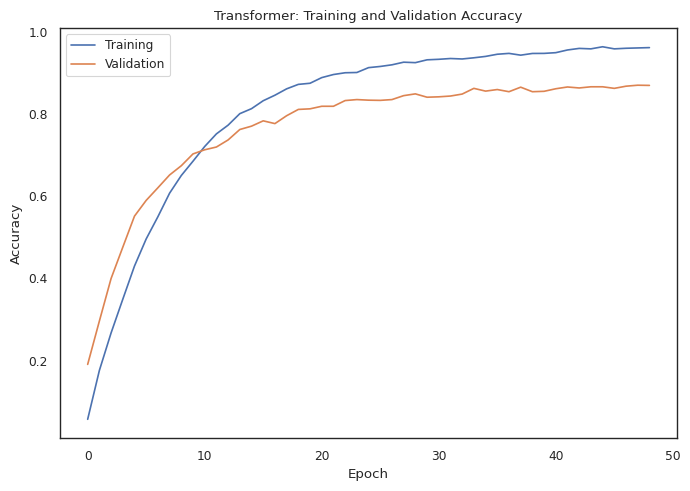

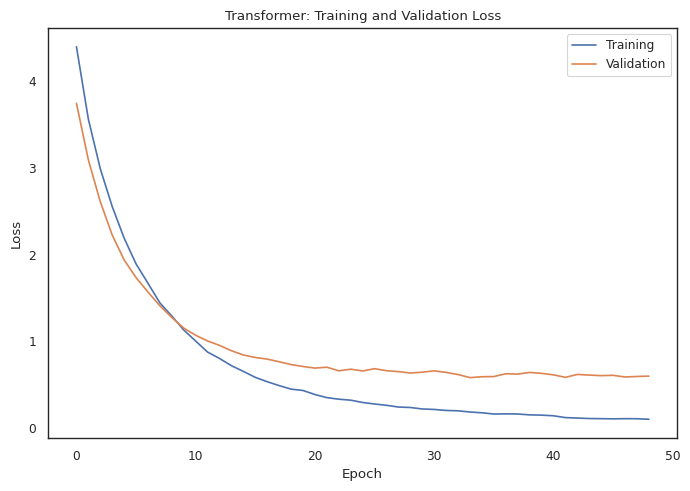

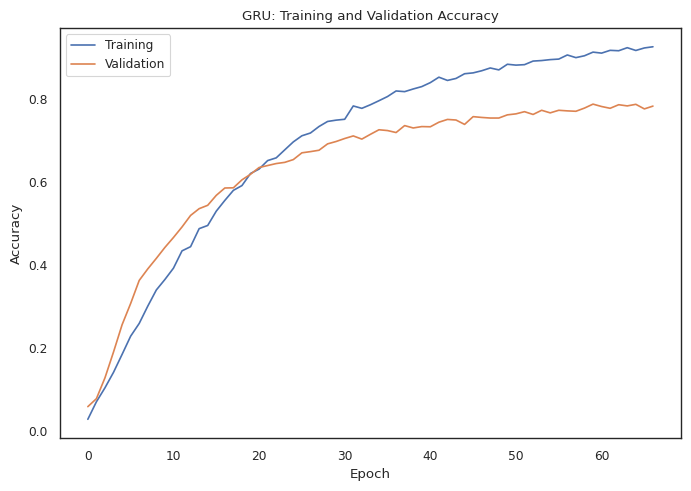

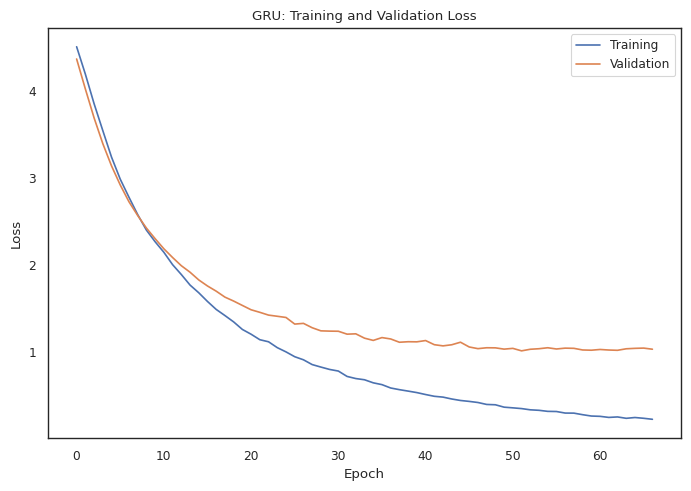

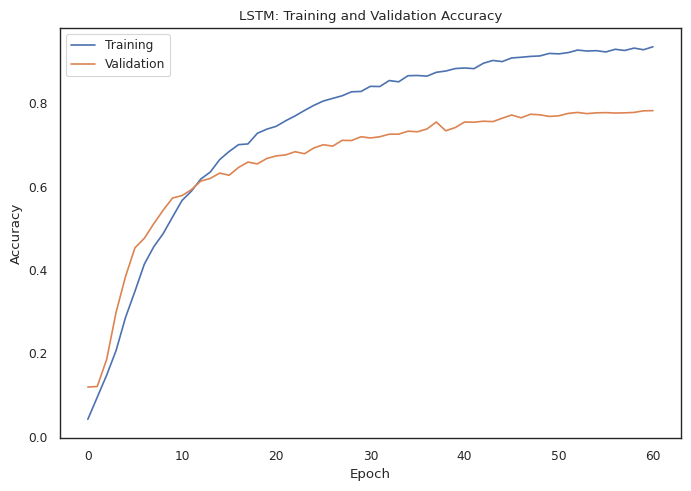

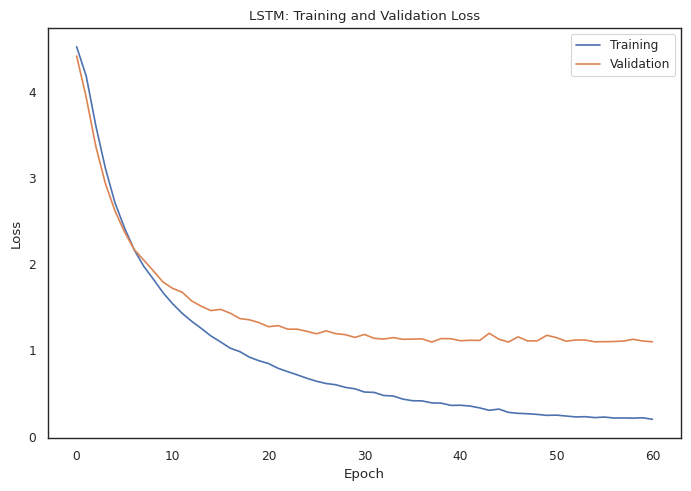


Evaluating Transformer...
33/33 ━━━━━━━━━━━━━━━━━━━━ 8s 239ms/step


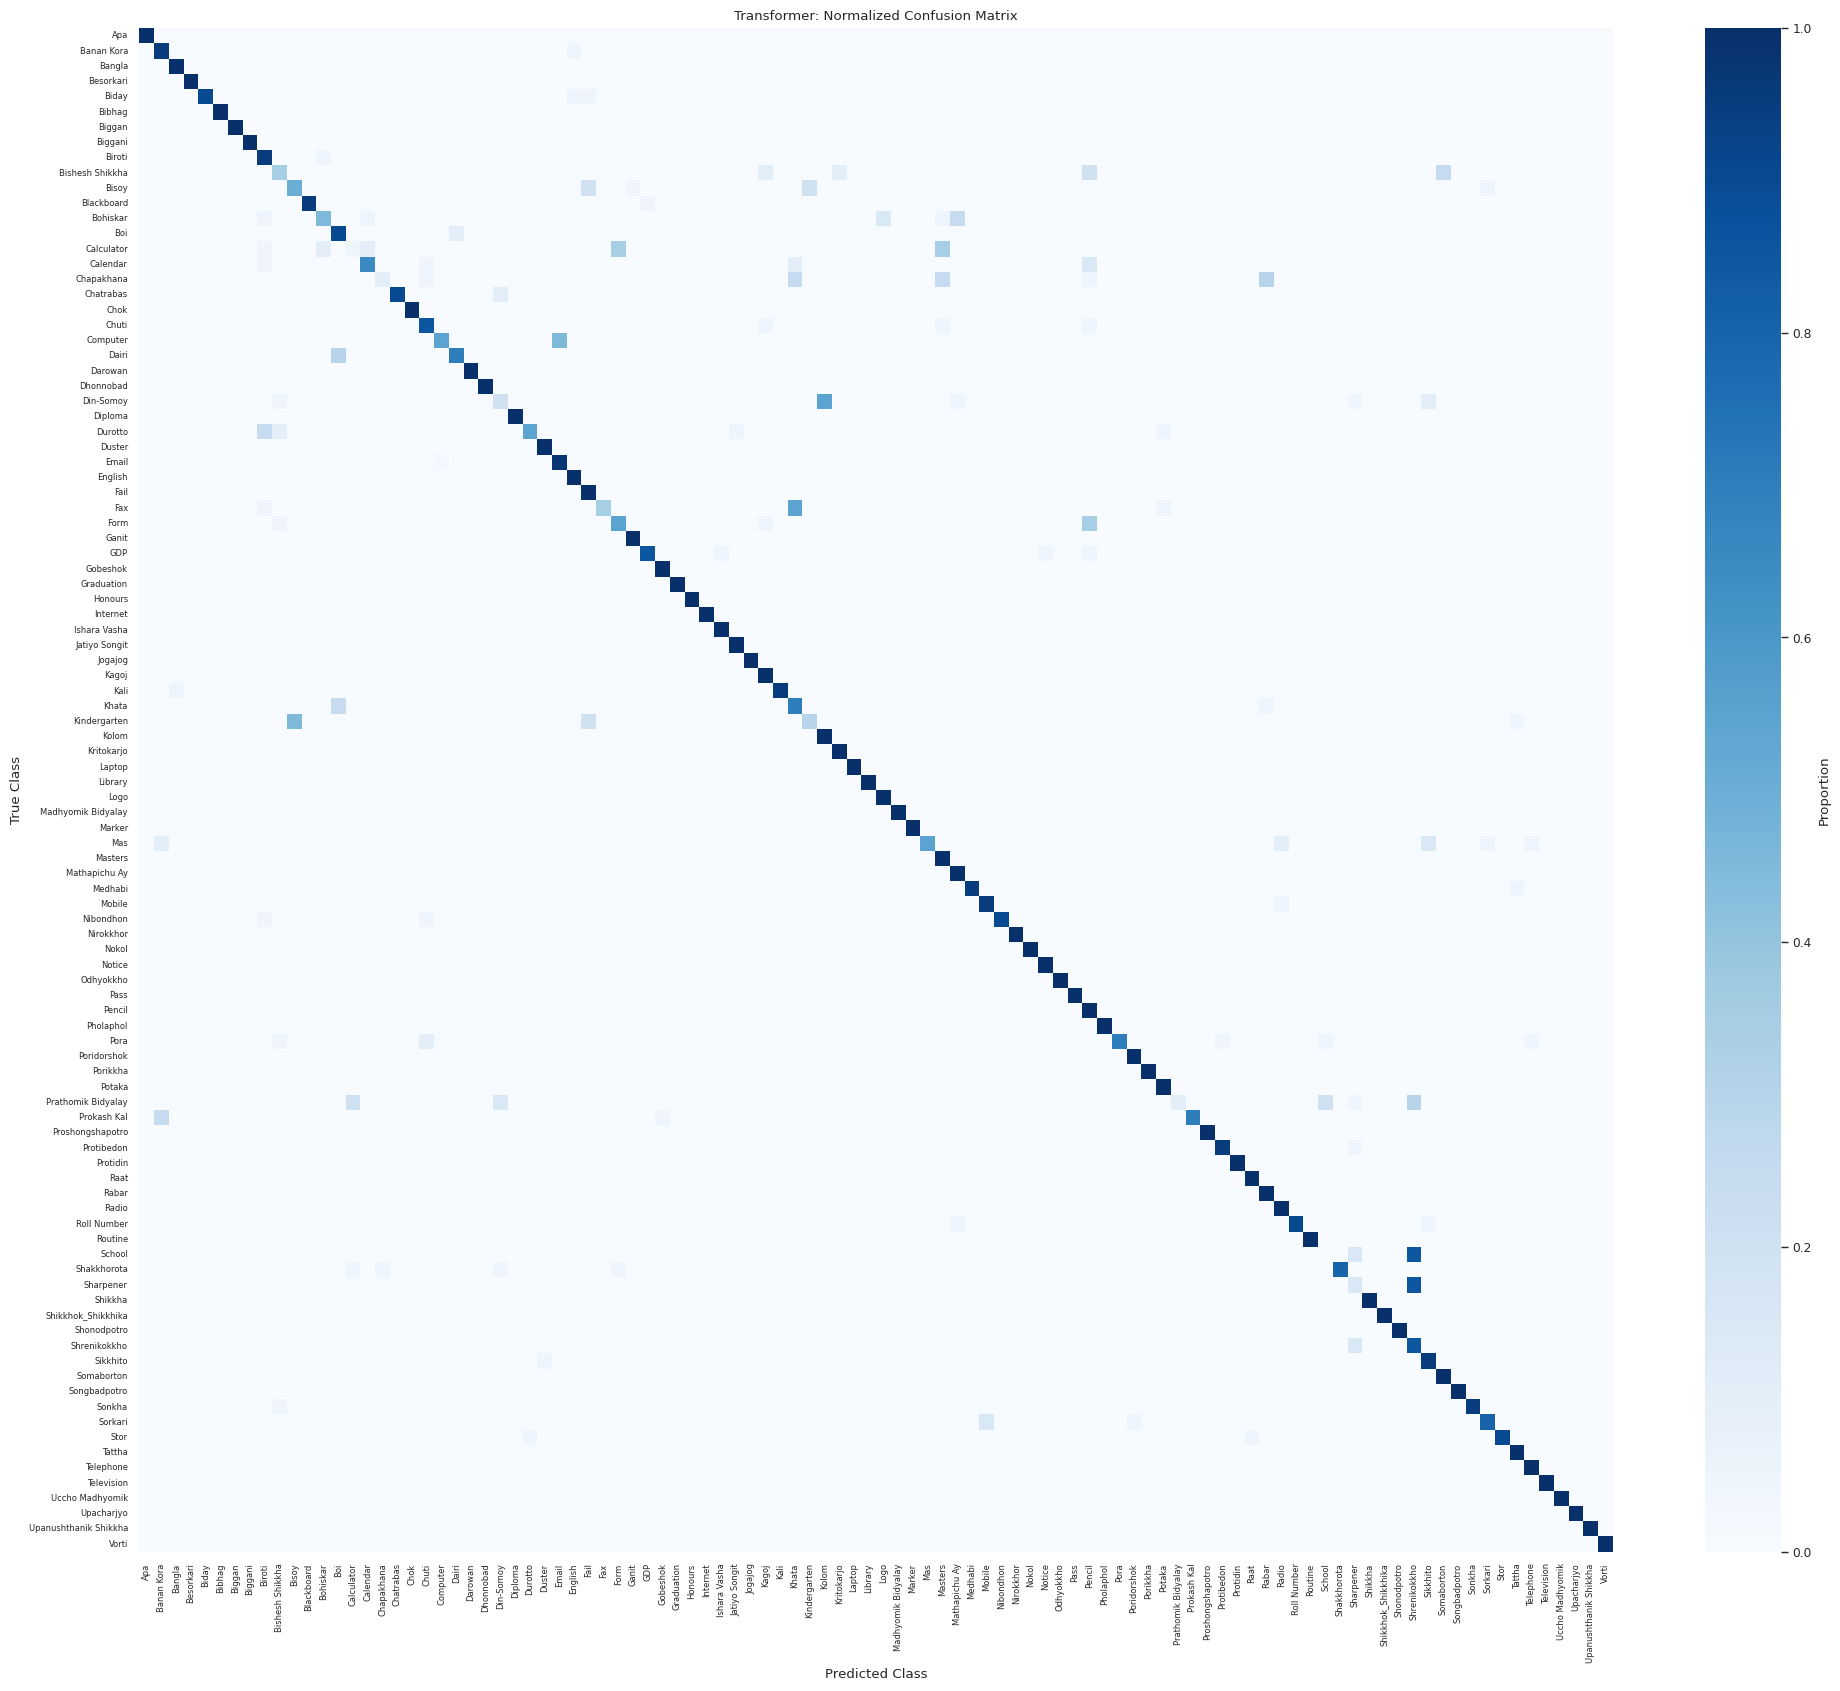


Evaluating GRU...
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step


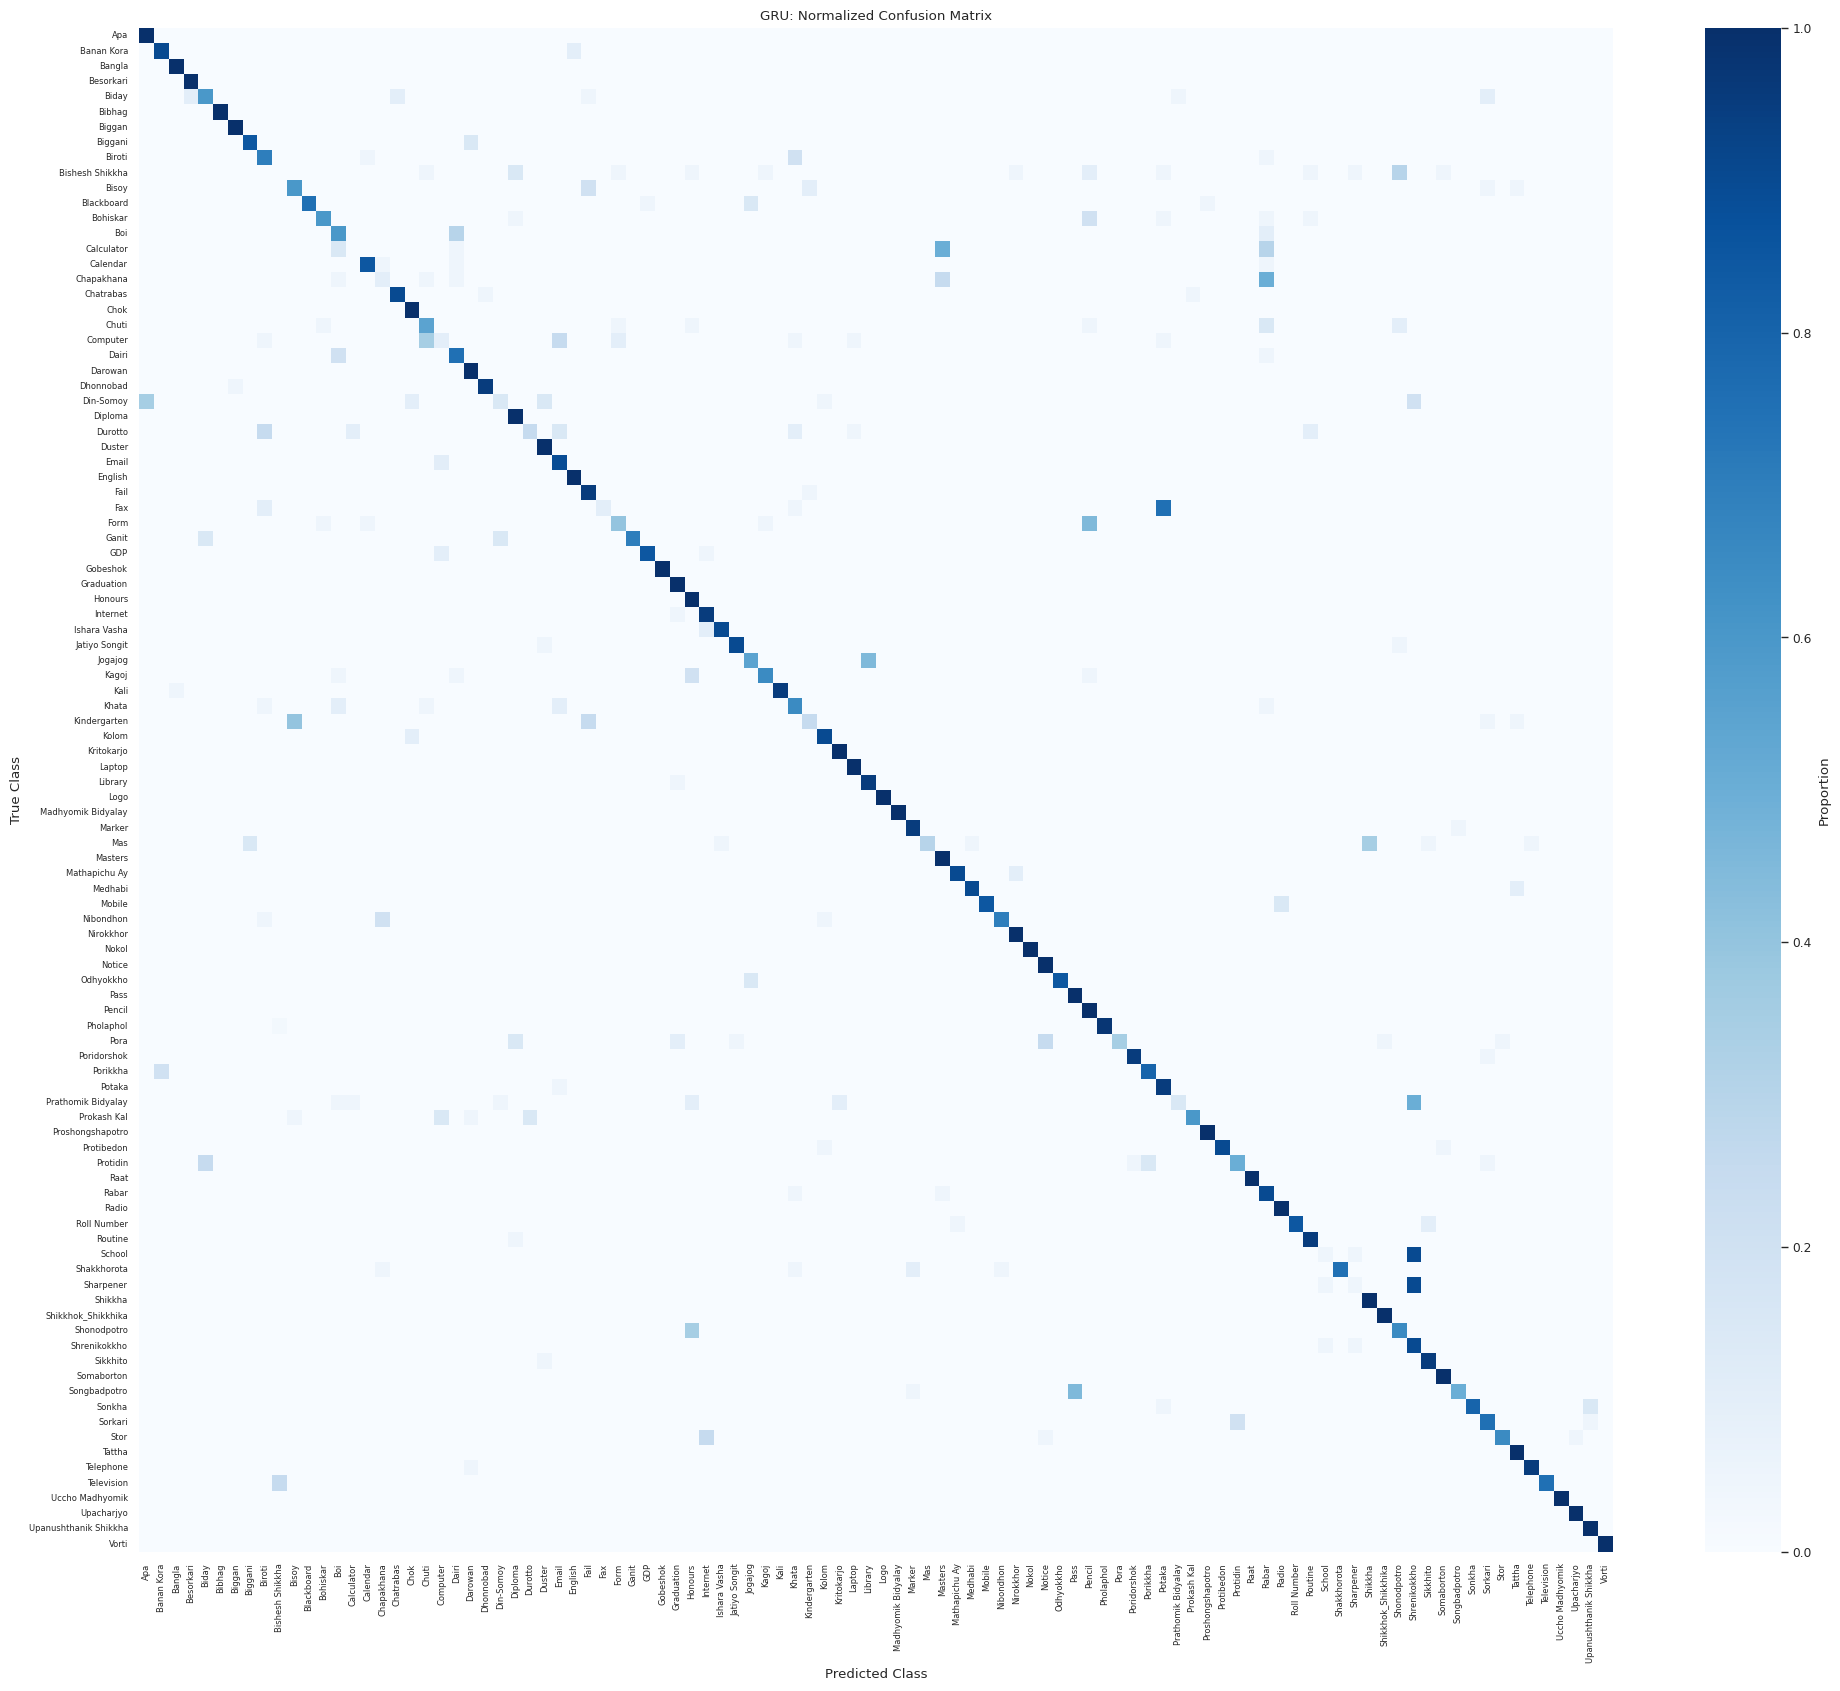


Evaluating LSTM...
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


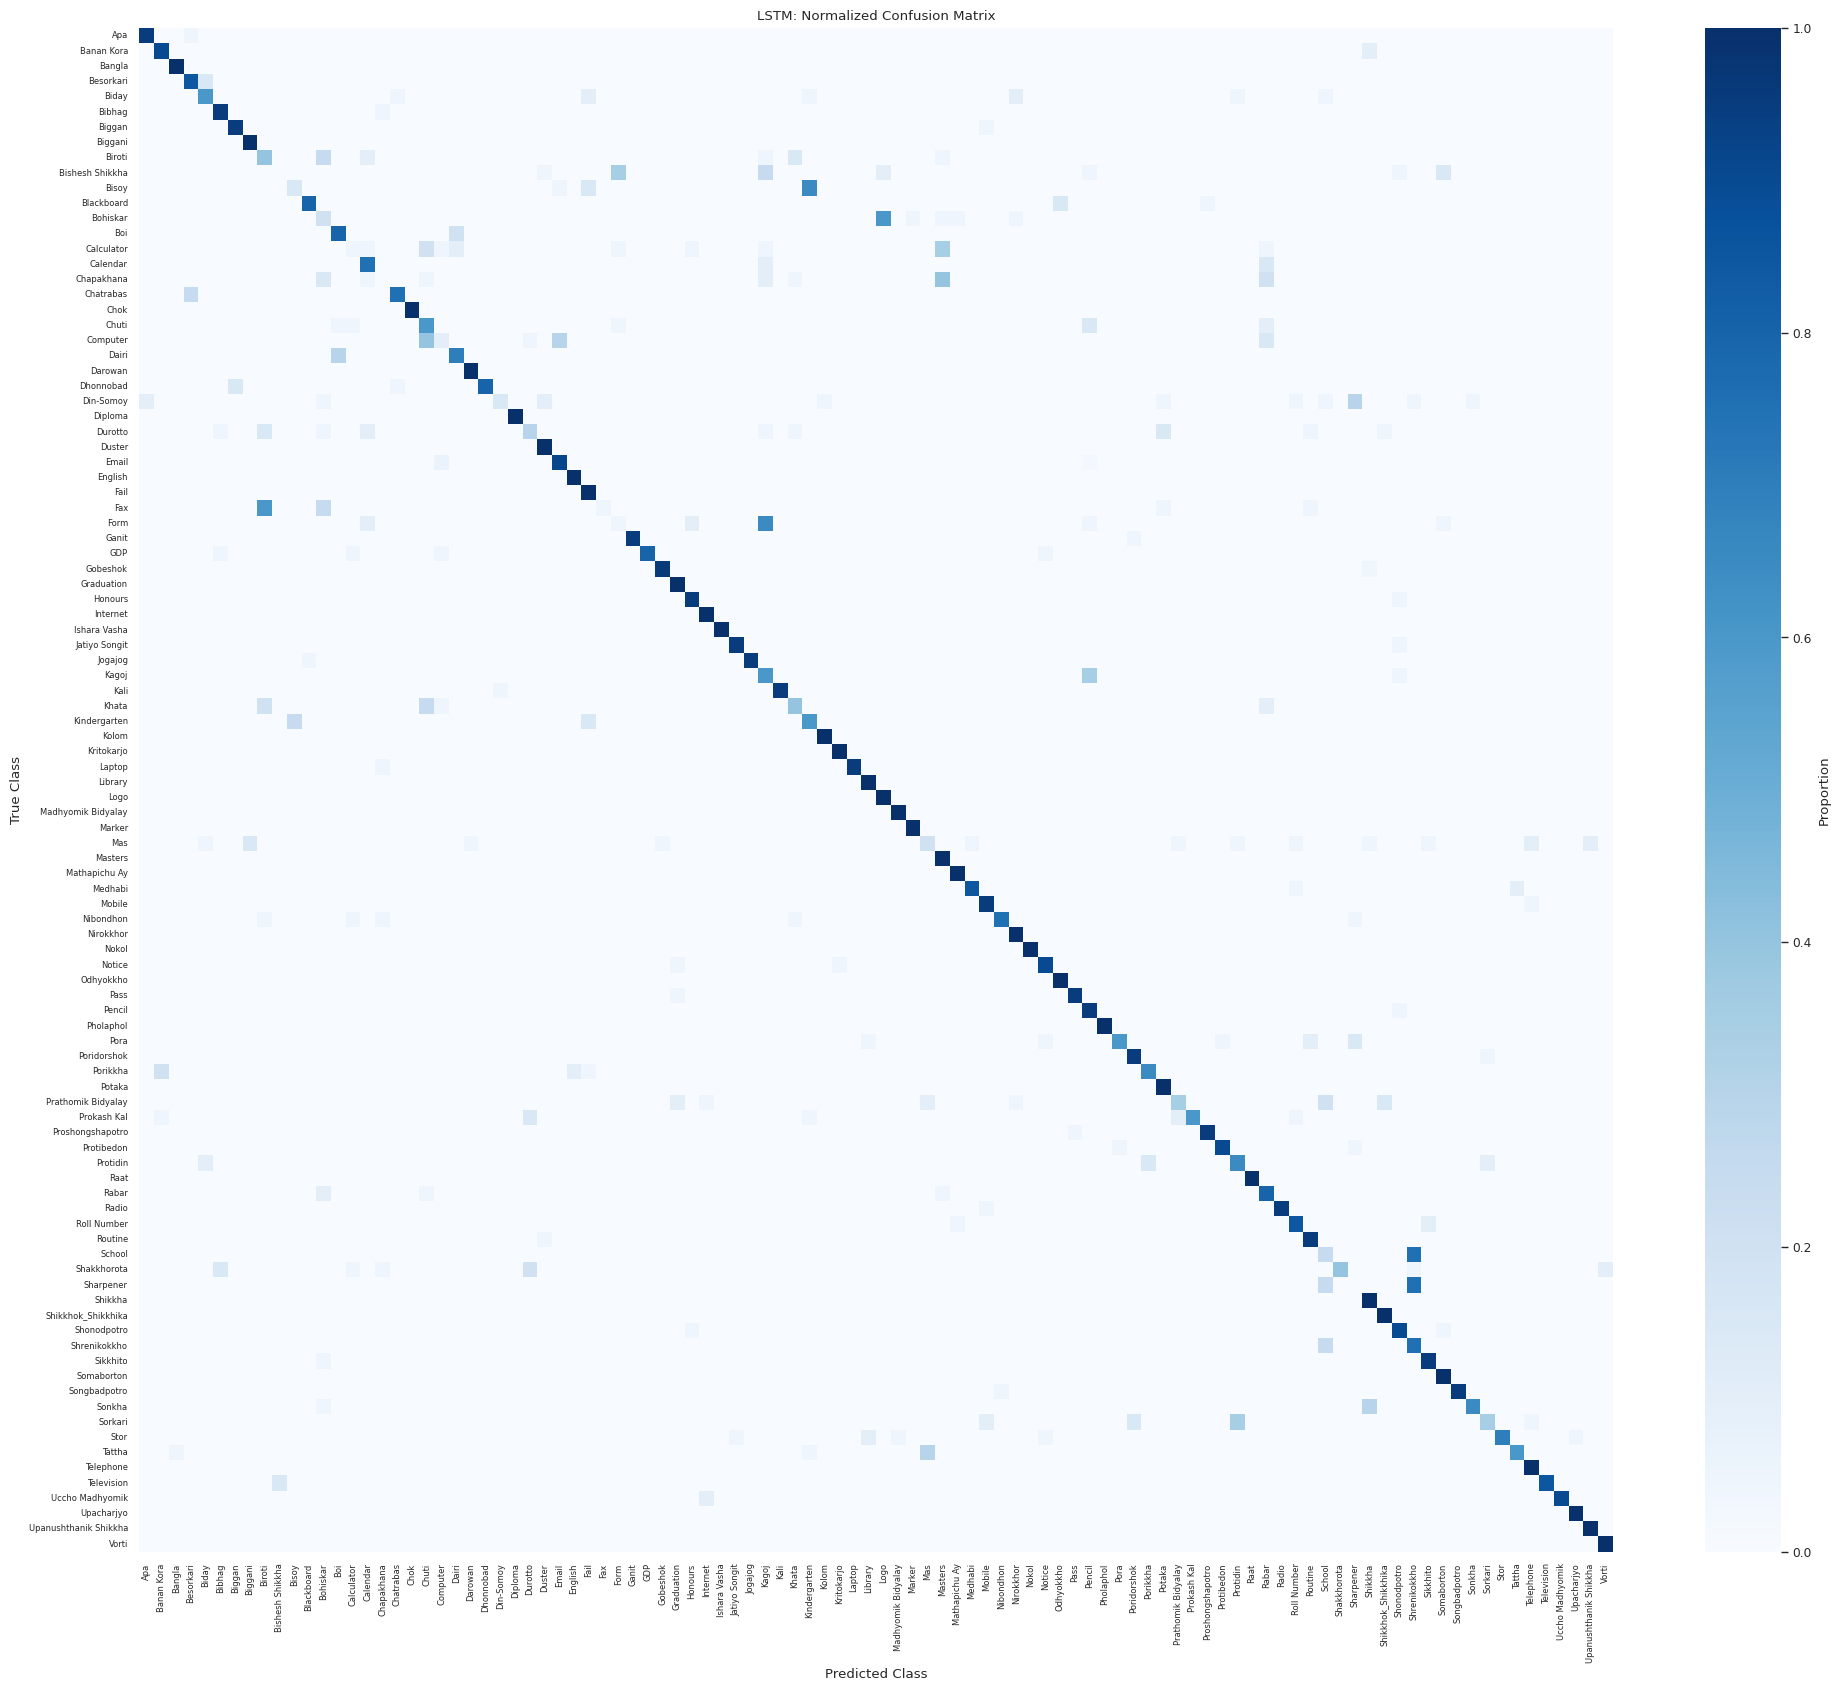


TEST-SET COMPARISON


,Model,Test_Accuracy,Weighted_Precision,Weighted_Recall,Weighted_F1,Macro_Precision,Macro_Recall,Macro_F1
0,Transformer,0.8689,0.8757,0.8689,0.8561,0.8726,0.8628,0.8507
1,GRU,0.7869,0.7945,0.7869,0.7667,0.7879,0.7782,0.7579
2,LSTM,0.7774,0.7742,0.7774,0.7580,0.7660,0.7682,0.7485


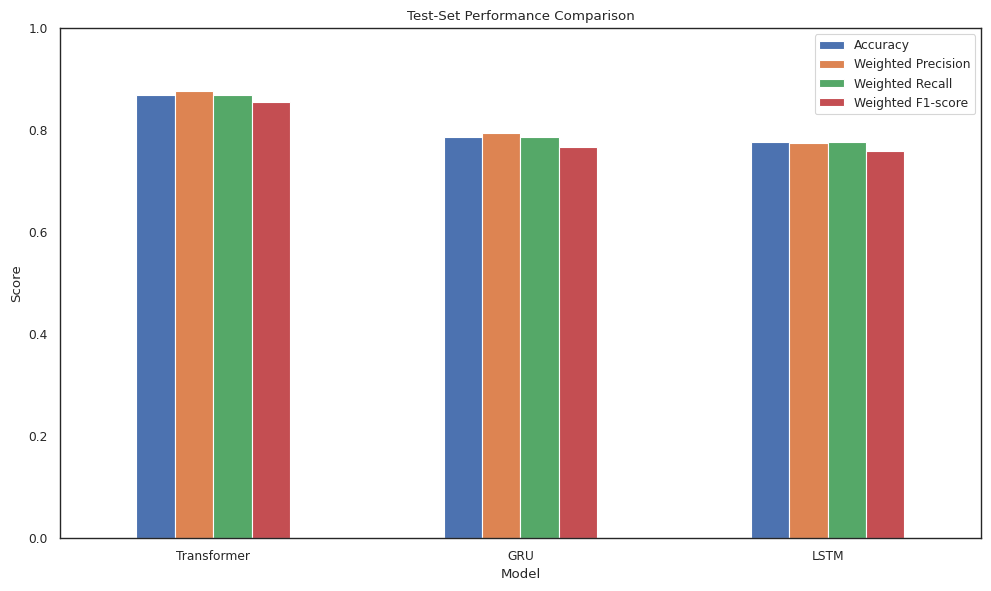


Saved results in: /content/BdSL_Journal_Results
ZIP archive: /content/BdSL_Journal_Results.zip
Files included:
 - gru_accuracy_curve.png
 - gru_classification_report.csv
 - gru_confusion_matrix_counts.csv
 - gru_loss_curve.png
 - gru_normalized_confusion_matrix.png
 - lstm_accuracy_curve.png
 - lstm_classification_report.csv
 - lstm_confusion_matrix_counts.csv
 - lstm_loss_curve.png
 - lstm_normalized_confusion_matrix.png
 - model_comparison_metrics.csv
 - model_performance_comparison.png
 - transformer_accuracy_curve.png
 - transformer_classification_report.csv
 - transformer_confusion_matrix_counts.csv
 - transformer_loss_curve.png
 - transformer_normalized_confusion_matrix.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:

# ============================================================
# BdSL JOURNAL RESULTS EXPORT
# Models: Transformer, GRU, LSTM
# Dataset input: X_test, y_int_test
# Output: PNG figures + CSV metrics + ZIP archive
# ============================================================

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from google.colab import files

# ------------------------------------------------------------
# 1. Check that the required notebook variables exist
# ------------------------------------------------------------

required_variables = [
    "X_test", "y_int_test", "NUM_CLASSES",
    "transformer_model", "gru_model", "lstm_model",
    "history_transformer", "history_gru", "history_lstm"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise NameError(
        "Missing variables: " + ", ".join(missing) +
        "\nRun the corresponding data/model cells first."
    )

# Use your existing ordered class names if available.
if "actions" in globals() and len(actions) == NUM_CLASSES:
    class_names = [str(x) for x in actions]
else:
    class_names = [f"Class_{i}" for i in range(NUM_CLASSES)]

# Output folder
OUTPUT_DIR = "/content/BdSL_Journal_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="white", context="paper")

# Ground-truth labels: integer class IDs
y_true = np.asarray(y_int_test).reshape(-1).astype(int)

assert len(y_true) == len(X_test), (
    "X_test and y_int_test have different lengths."
)
assert np.all((y_true >= 0) & (y_true < NUM_CLASSES)), (
    "Test labels are outside the expected class range."
)

models = {
    "Transformer": {
        "model": transformer_model,
        "history": history_transformer
    },
    "GRU": {
        "model": gru_model,
        "history": history_gru
    },
    "LSTM": {
        "model": lstm_model,
        "history": history_lstm
    }
}

# ------------------------------------------------------------
# 2. Plot training and validation accuracy/loss curves
# ------------------------------------------------------------

def find_history_key(history_dict, candidates):
    for key in candidates:
        if key in history_dict:
            return key
    return None

for model_name, info in models.items():
    hist_obj = info["history"]

    # Keras History object or history dictionary
    hist = (
        hist_obj.history
        if hasattr(hist_obj, "history")
        else hist_obj
    )

    if not isinstance(hist, dict) or not hist:
        print(f"Skipping curves for {model_name}: no history found.")
        continue

    acc_key = find_history_key(
        hist, ["accuracy", "categorical_accuracy", "sparse_categorical_accuracy"]
    )
    val_acc_key = find_history_key(
        hist, ["val_accuracy", "val_categorical_accuracy",
               "val_sparse_categorical_accuracy"]
    )
    loss_key = find_history_key(hist, ["loss"])
    val_loss_key = find_history_key(hist, ["val_loss"])

    # Accuracy curve
    if acc_key:
        plt.figure(figsize=(7, 5))
        plt.plot(hist[acc_key], label="Training")
        if val_acc_key:
            plt.plot(hist[val_acc_key], label="Validation")

        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title(f"{model_name}: Training and Validation Accuracy")
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                f"{model_name.lower()}_accuracy_curve.png"
            ),
            dpi=400, bbox_inches="tight"
        )
        plt.show()
        plt.close()

    # Loss curve
    if loss_key:
        plt.figure(figsize=(7, 5))
        plt.plot(hist[loss_key], label="Training")
        if val_loss_key:
            plt.plot(hist[val_loss_key], label="Validation")

        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title(f"{model_name}: Training and Validation Loss")
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                f"{model_name.lower()}_loss_curve.png"
            ),
            dpi=400, bbox_inches="tight"
        )
        plt.show()
        plt.close()

# ------------------------------------------------------------
# 3. Evaluate all three models on the SAME test set
# ------------------------------------------------------------

summary_rows = []
classification_reports = {}

for model_name, info in models.items():
    print(f"\nEvaluating {model_name}...")

    probabilities = info["model"].predict(
        X_test, batch_size=64, verbose=1
    )

    y_pred = np.argmax(probabilities, axis=1)

    # Core metrics
    acc = accuracy_score(y_true, y_pred)

    # Weighted metrics account for class support.
    precision_weighted = precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    recall_weighted = recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    f1_weighted = f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    )

    # Macro metrics give equal weight to each class.
    precision_macro = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall_macro = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1_macro = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    summary_rows.append({
        "Model": model_name,
        "Test_Accuracy": acc,
        "Weighted_Precision": precision_weighted,
        "Weighted_Recall": recall_weighted,
        "Weighted_F1": f1_weighted,
        "Macro_Precision": precision_macro,
        "Macro_Recall": recall_macro,
        "Macro_F1": f1_macro
    })

    # Full class-wise report
    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()
    report_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name.lower()}_classification_report.csv"
        ),
        index=True
    )

    classification_reports[model_name] = report_df

    # Normalized confusion matrix: row-normalized by true class
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        normalize="true"
    )

    plt.figure(figsize=(20, 17))
    sns.heatmap(
        cm,
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=class_names,
        yticklabels=class_names,
        cbar_kws={"label": "Proportion"}
    )

    plt.title(f"{model_name}: Normalized Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.xticks(rotation=90, fontsize=6)
    plt.yticks(rotation=0, fontsize=6)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name.lower()}_normalized_confusion_matrix.png"
        ),
        dpi=400, bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # Also save raw confusion matrix counts
    cm_counts = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES))
    )
    pd.DataFrame(
        cm_counts,
        index=class_names,
        columns=class_names
    ).to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model_name.lower()}_confusion_matrix_counts.csv"
        )
    )

# ------------------------------------------------------------
# 4. Save model comparison metrics
# ------------------------------------------------------------

results_df = pd.DataFrame(summary_rows)
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison_metrics.csv"),
    index=False
)

print("\nTEST-SET COMPARISON")
display(
    results_df.style.format({
        col: "{:.4f}"
        for col in results_df.select_dtypes(include="number").columns
    })
)

# Comparison chart: accuracy, weighted precision, recall and F1
comparison_columns = {
    "Test_Accuracy": "Accuracy",
    "Weighted_Precision": "Weighted Precision",
    "Weighted_Recall": "Weighted Recall",
    "Weighted_F1": "Weighted F1-score"
}

plot_df = results_df.set_index("Model")[
    list(comparison_columns.keys())
].rename(columns=comparison_columns)

ax = plot_df.plot(
    kind="bar", figsize=(10, 6), ylim=(0, 1), rot=0
)
ax.set_ylabel("Score")
ax.set_title("Test-Set Performance Comparison")
ax.legend(loc="best")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "model_performance_comparison.png"),
    dpi=400, bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 5. Package all output files into one ZIP
# ------------------------------------------------------------

zip_path = "/content/BdSL_Journal_Results.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for filename in sorted(os.listdir(OUTPUT_DIR)):
        full_path = os.path.join(OUTPUT_DIR, filename)
        if os.path.isfile(full_path):
            zf.write(full_path, arcname=filename)

print(f"\nSaved results in: {OUTPUT_DIR}")
print(f"ZIP archive: {zip_path}")
print("Files included:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)

# Download all figures, reports, and metric tables together
files.download(zip_path)


Predicting with Transformer...
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step
Predicting with GRU...
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
Predicting with LSTM...
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step


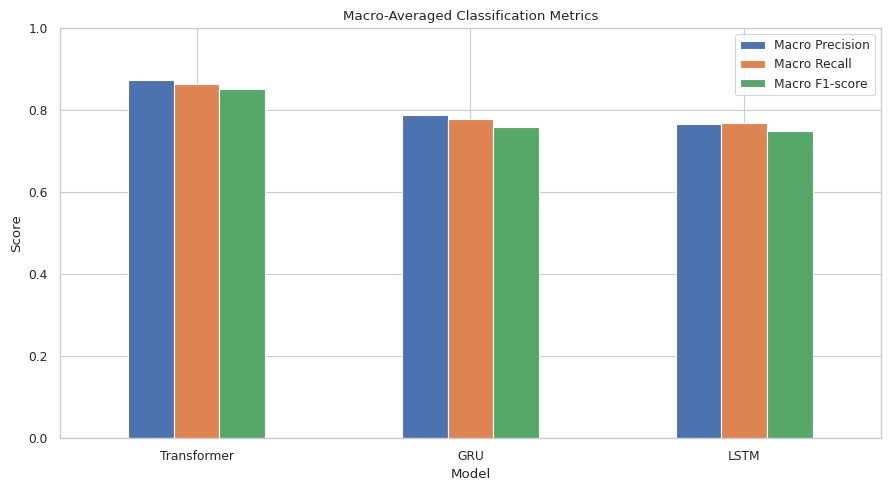

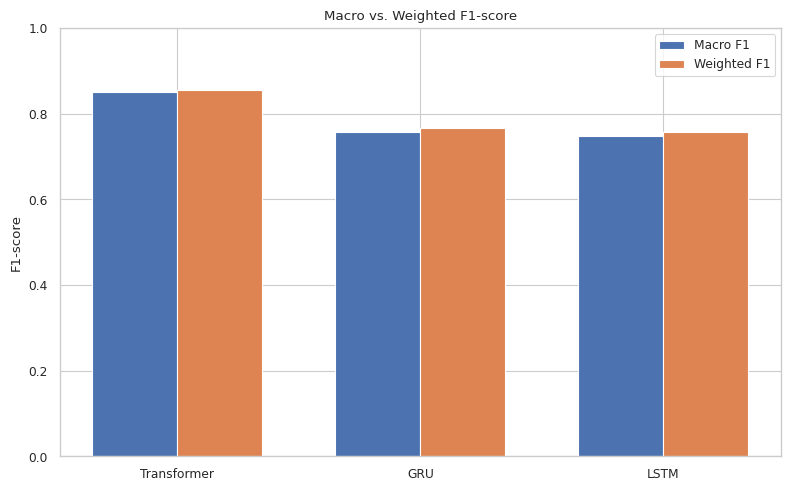

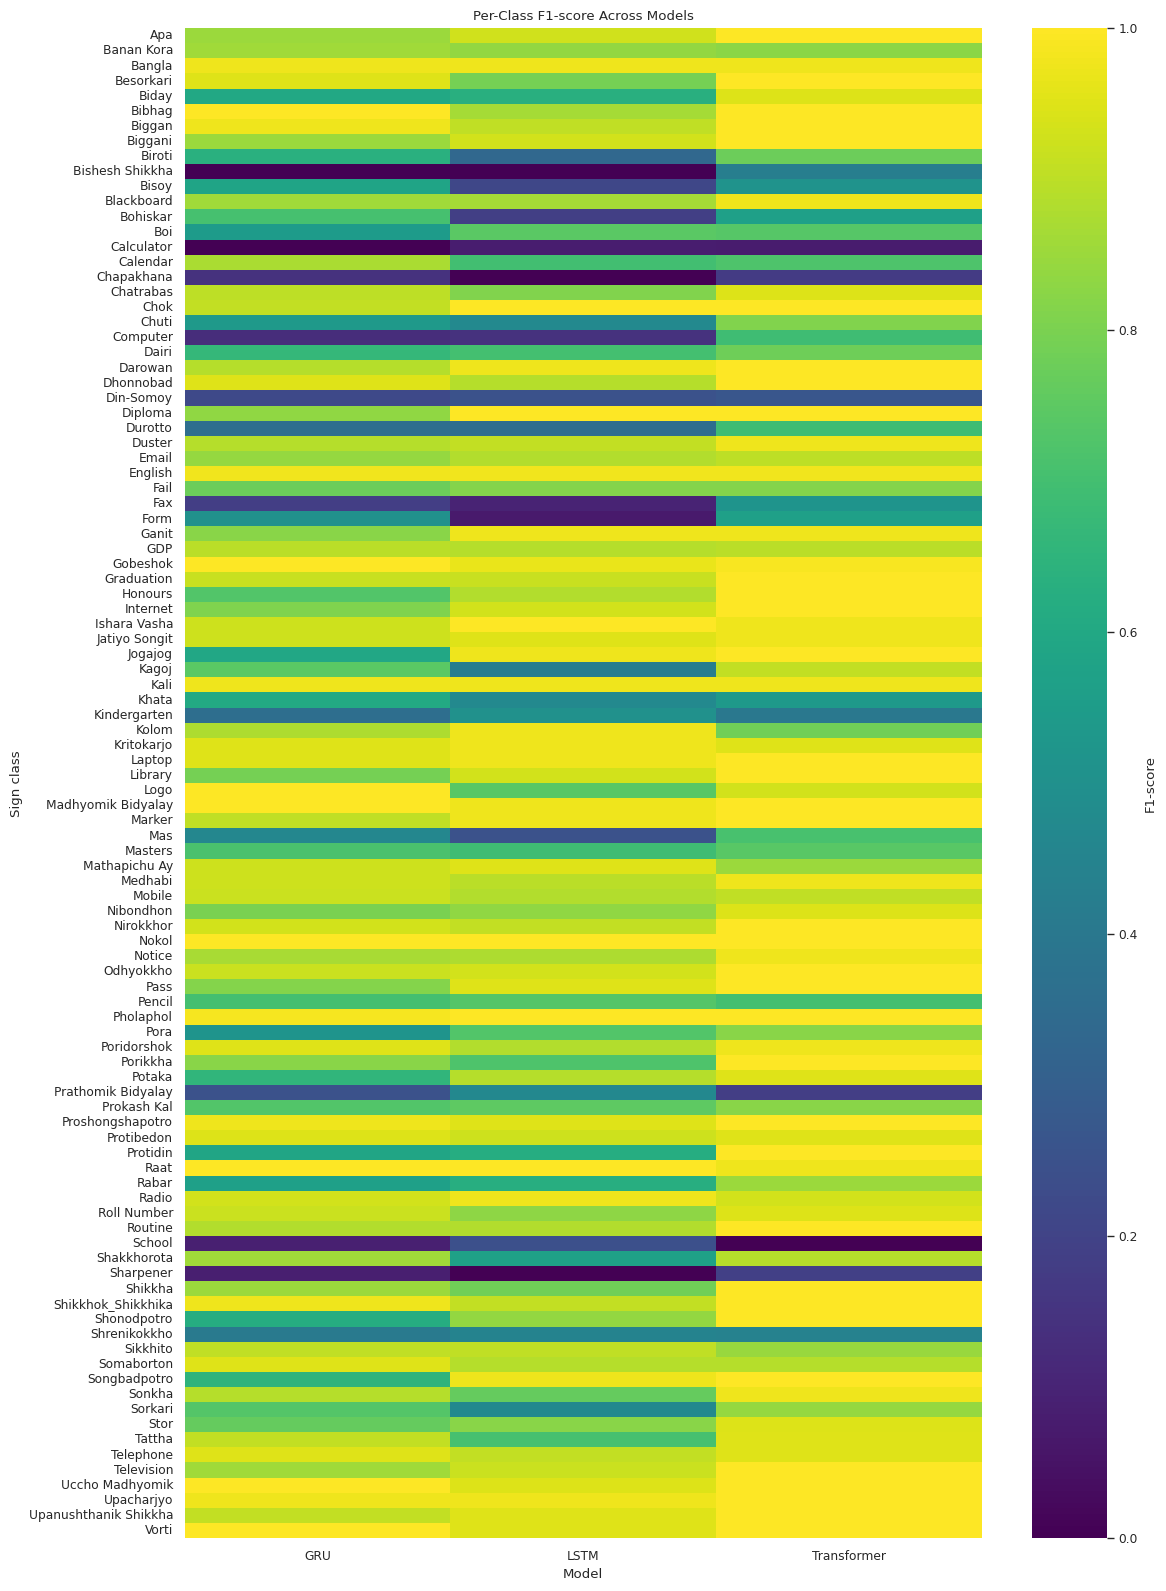

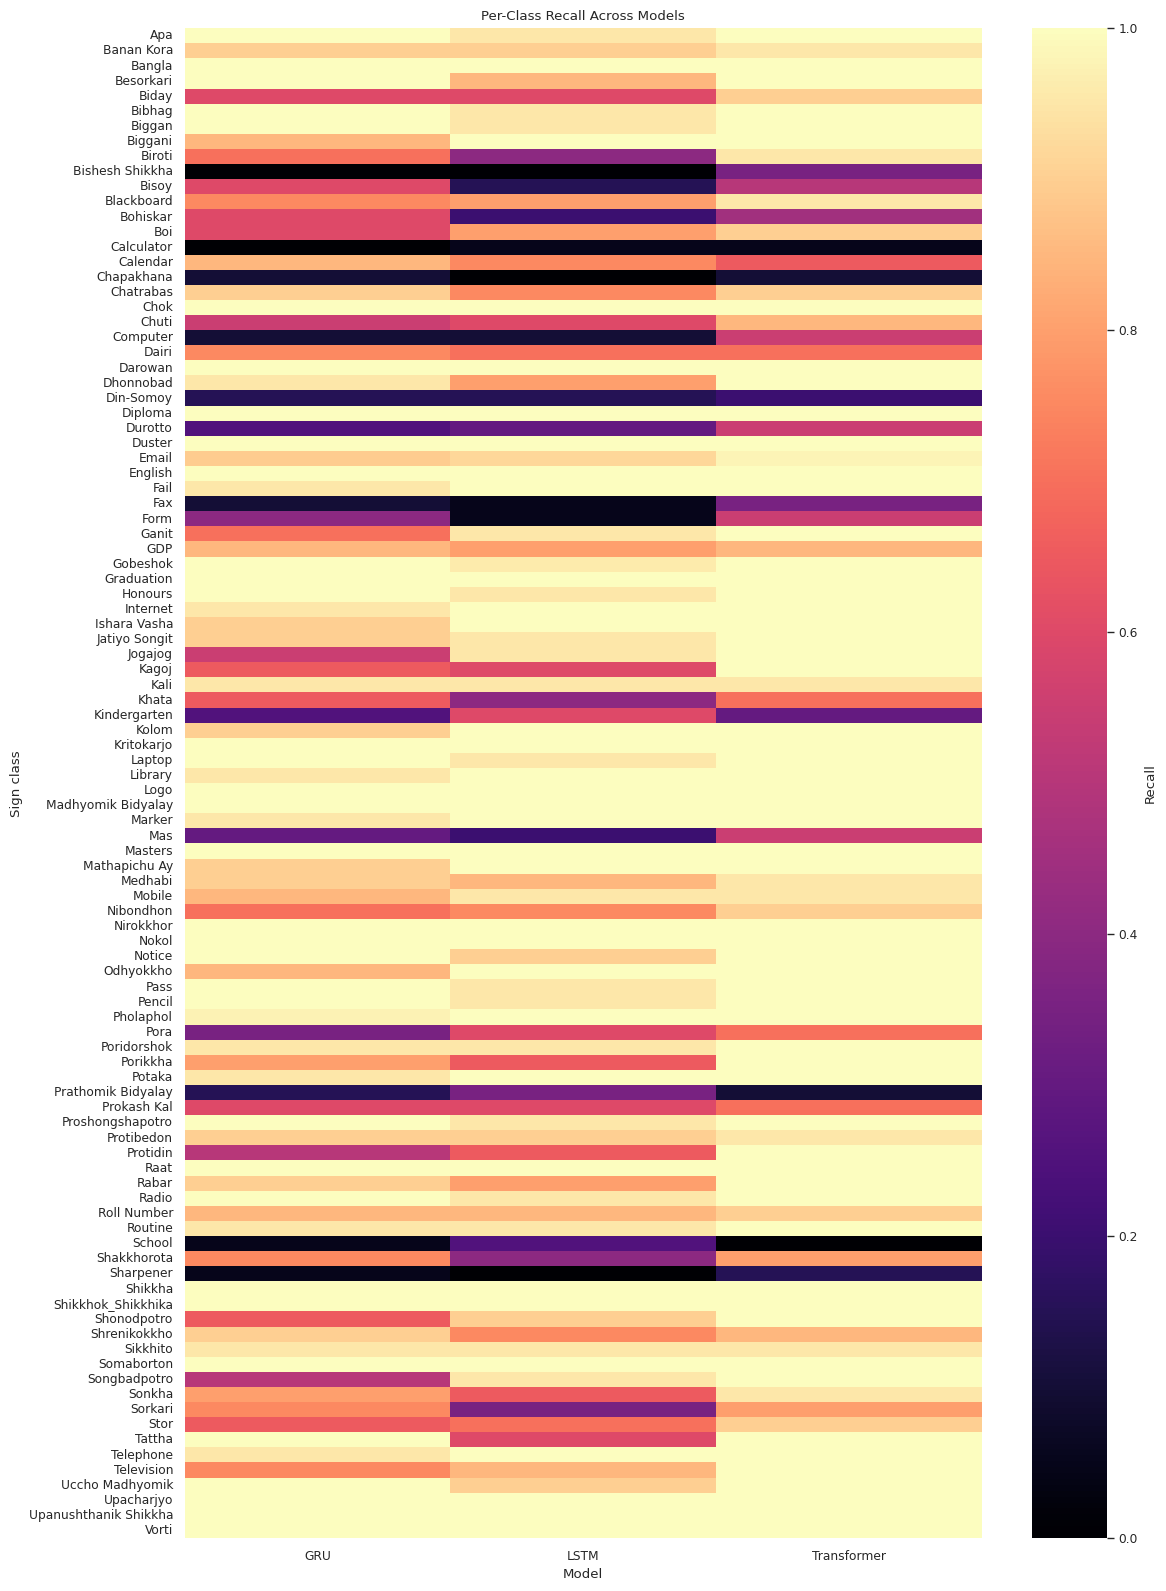

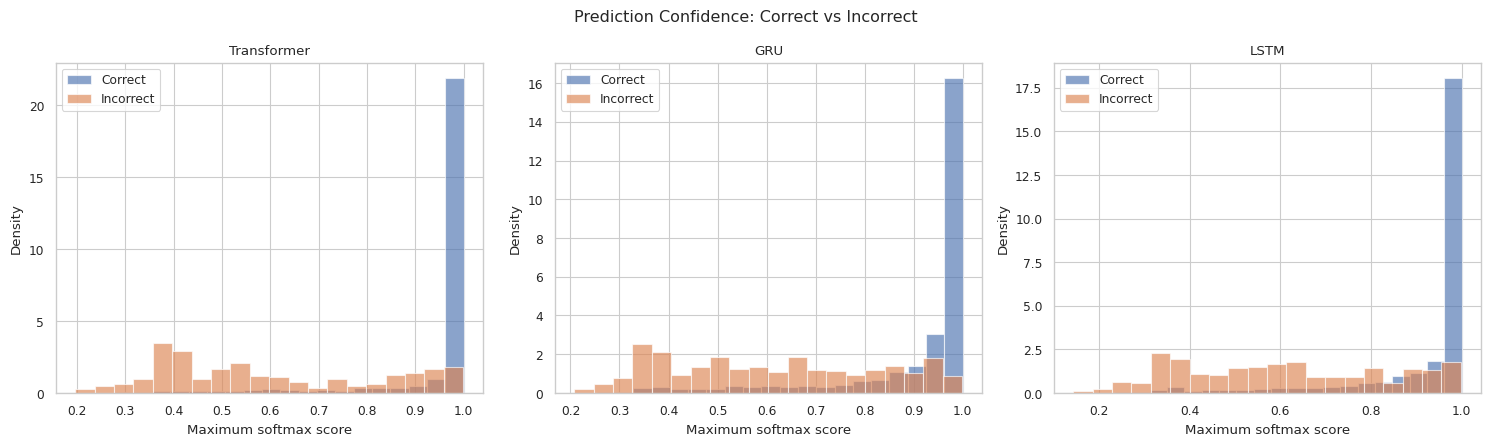

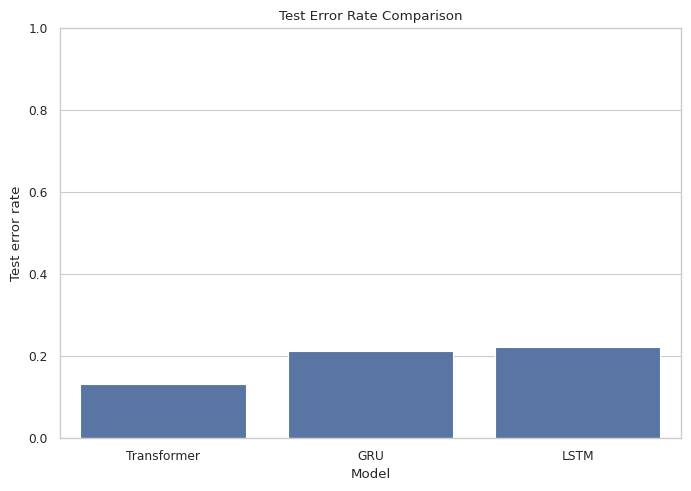

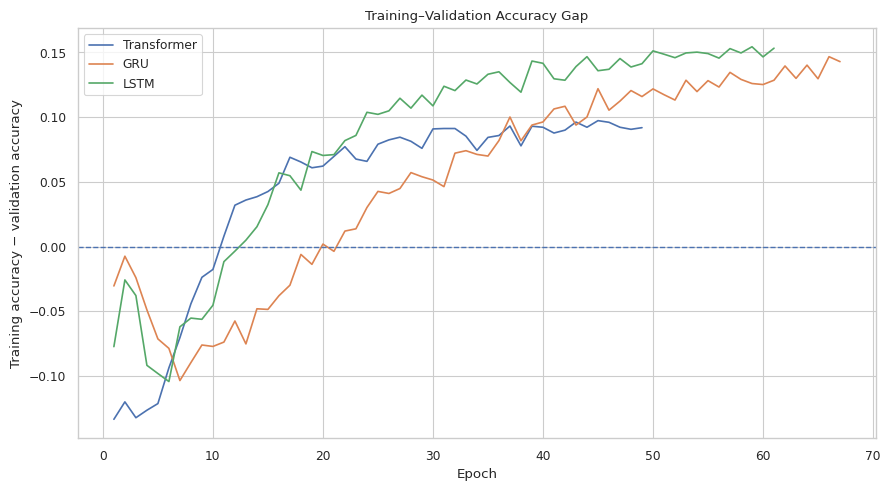

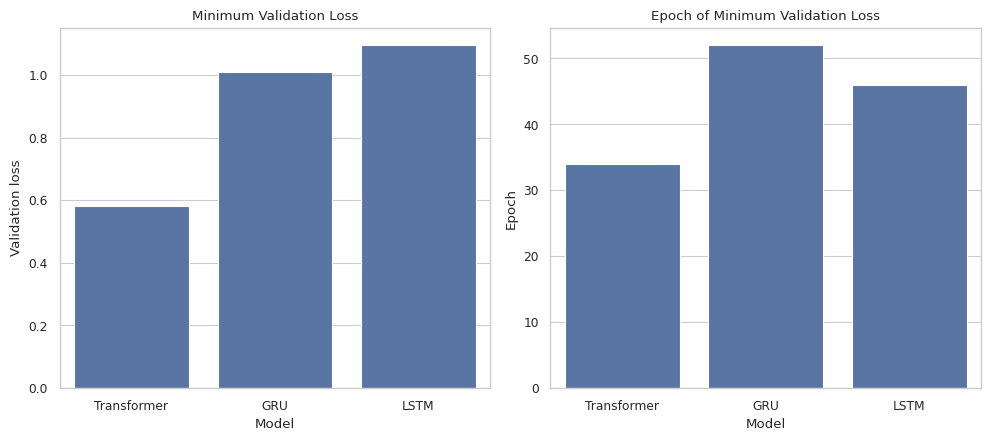

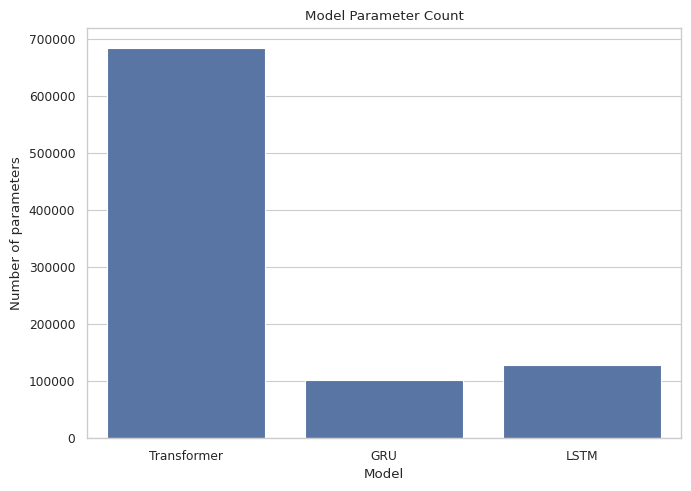

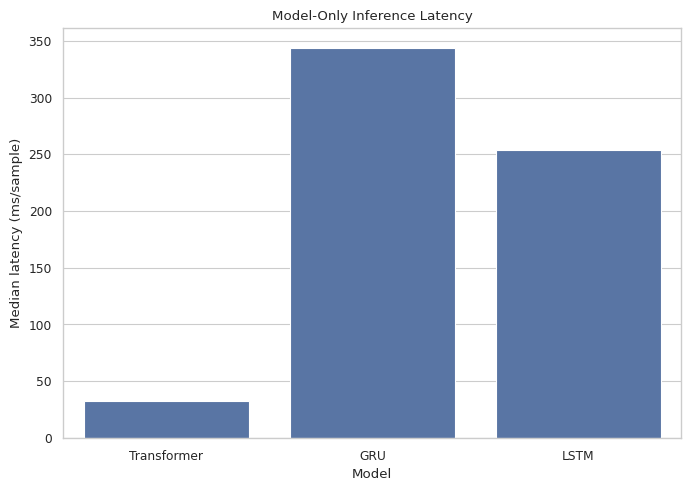


Generated files:
 - 01_macro_metric_comparison.png
 - 02_macro_vs_weighted_f1.png
 - 03_per_class_f1_heatmap.png
 - 04_per_class_recall_heatmap.png
 - 05_prediction_confidence.png
 - 06_test_error_rate.png
 - 07_generalization_gap.png
 - 08_validation_convergence.png
 - 09_model_parameter_count.png
 - 10_model_inference_latency.png
 - best_validation_loss.csv
 - generalization_gap_by_epoch.csv
 - model_only_inference_latency.csv
 - model_parameter_counts.csv
 - overall_metrics.csv
 - per_class_metrics.csv

Overall test metrics:


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Error_Rate
0,Transformer,0.868923,0.872634,0.862787,0.850723,0.875729,0.868923,0.856053,0.131077
1,GRU,0.786940,0.787869,0.778180,0.757918,0.794483,0.786940,0.766726,0.213060
2,LSTM,0.777407,0.765980,0.768232,0.748496,0.774202,0.777407,0.758040,0.222593



Per-class metrics preview:


,Model,Class,Precision,Recall,F1,Support
0,Transformer,Apa,1.000000,1.00,1.000000,20.0
1,Transformer,Banan Kora,0.730769,0.95,0.826087,20.0
2,Transformer,Bangla,0.952381,1.00,0.975610,20.0
3,Transformer,Besorkari,1.000000,1.00,1.000000,20.0
4,Transformer,Biday,1.000000,0.90,0.947368,20.0



Inference latency:


,Model,Mean_Latency_ms,Median_Latency_ms,Std_Latency_ms
0,Transformer,33.656799,32.464893,3.701083
1,GRU,369.014141,343.998784,56.040638
2,LSTM,271.966236,253.883465,42.738355


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:

# ============================================================
# ADDITIONAL JOURNAL FIGURES FOR BdSL RECOGNITION
# Models: Transformer, GRU, LSTM
# Uses actual predictions and training histories
# ============================================================

import os
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)
from google.colab import files

# ------------------------------------------------------------
# 1. Verify variables from your existing notebook
# ------------------------------------------------------------

required = [
    "X_test", "y_int_test", "NUM_CLASSES",
    "transformer_model", "gru_model", "lstm_model",
    "history_transformer", "history_gru", "history_lstm"
]
missing = [v for v in required if v not in globals()]

if missing:
    raise NameError(
        "Run the relevant data/model cells first. Missing: "
        + ", ".join(missing)
    )

OUT = "/content/BdSL_Additional_Figures"
os.makedirs(OUT, exist_ok=True)

sns.set_theme(style="whitegrid", context="paper")

if "actions" in globals() and len(actions) == NUM_CLASSES:
    class_names = [str(a) for a in actions]
else:
    class_names = [f"Class_{i}" for i in range(NUM_CLASSES)]

y_true = np.asarray(y_int_test).reshape(-1).astype(int)

assert len(y_true) == len(X_test)
assert np.all((y_true >= 0) & (y_true < NUM_CLASSES))

models = {
    "Transformer": (transformer_model, history_transformer),
    "GRU": (gru_model, history_gru),
    "LSTM": (lstm_model, history_lstm)
}

# ------------------------------------------------------------
# 2. Obtain real test predictions
# ------------------------------------------------------------

probabilities = {}
predictions = {}
confidence = {}

for name, (model, history) in models.items():
    print(f"Predicting with {name}...")
    p = model.predict(X_test, batch_size=64, verbose=1)

    if p.ndim != 2 or p.shape[1] != NUM_CLASSES:
        raise ValueError(
            f"{name} output shape {p.shape} does not match "
            f"NUM_CLASSES={NUM_CLASSES}."
        )

    probabilities[name] = p
    predictions[name] = np.argmax(p, axis=1)
    confidence[name] = np.max(p, axis=1)

# ------------------------------------------------------------
# 3. Collect overall and per-class metrics
# ------------------------------------------------------------

overall_rows = []
per_class = {}

for name in models:
    yp = predictions[name]

    overall_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, yp),
        "Macro_Precision": precision_score(
            y_true, yp, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true, yp, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true, yp, average="macro", zero_division=0
        ),
        "Weighted_Precision": precision_score(
            y_true, yp, average="weighted", zero_division=0
        ),
        "Weighted_Recall": recall_score(
            y_true, yp, average="weighted", zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_true, yp, average="weighted", zero_division=0
        ),
        "Error_Rate": np.mean(yp != y_true)
    })

    rep = classification_report(
        y_true, yp,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for i, cls in enumerate(class_names):
        per_class[(name, cls)] = {
            "Model": name,
            "Class": cls,
            "Precision": rep[cls]["precision"],
            "Recall": rep[cls]["recall"],
            "F1": rep[cls]["f1-score"],
            "Support": rep[cls]["support"]
        }

overall_df = pd.DataFrame(overall_rows)
class_df = pd.DataFrame(list(per_class.values()))

overall_df.to_csv(f"{OUT}/overall_metrics.csv", index=False)
class_df.to_csv(f"{OUT}/per_class_metrics.csv", index=False)

# ------------------------------------------------------------
# 4. Figure: Precision, recall, F1 comparison
# ------------------------------------------------------------

metric_cols = ["Macro_Precision", "Macro_Recall", "Macro_F1"]
metric_labels = ["Macro Precision", "Macro Recall", "Macro F1-score"]

plot_df = overall_df.set_index("Model")[metric_cols].copy()
plot_df.columns = metric_labels

ax = plot_df.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
ax.set_ylabel("Score")
ax.set_title("Macro-Averaged Classification Metrics")
plt.tight_layout()
plt.savefig(f"{OUT}/01_macro_metric_comparison.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 5. Figure: Macro-F1 vs weighted-F1
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(overall_df))
width = 0.35

ax.bar(x - width/2, overall_df["Macro_F1"], width,
       label="Macro F1")
ax.bar(x + width/2, overall_df["Weighted_F1"], width,
       label="Weighted F1")

ax.set_xticks(x)
ax.set_xticklabels(overall_df["Model"])
ax.set_ylim(0, 1)
ax.set_ylabel("F1-score")
ax.set_title("Macro vs. Weighted F1-score")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/02_macro_vs_weighted_f1.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 6. Figure: Per-class F1 score for every model
# 100 classes may make labels crowded; use a tall figure.
# ------------------------------------------------------------

f1_table = class_df.pivot(
    index="Class", columns="Model", values="F1"
)
f1_table = f1_table.reindex(class_names)

plt.figure(figsize=(12, max(10, NUM_CLASSES * 0.16)))
sns.heatmap(
    f1_table, vmin=0, vmax=1, cmap="viridis",
    yticklabels=True, cbar_kws={"label": "F1-score"}
)
plt.title("Per-Class F1-score Across Models")
plt.xlabel("Model")
plt.ylabel("Sign class")
plt.tight_layout()
plt.savefig(f"{OUT}/03_per_class_f1_heatmap.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 7. Figure: Per-class recall
# ------------------------------------------------------------

recall_table = class_df.pivot(
    index="Class", columns="Model", values="Recall"
).reindex(class_names)

plt.figure(figsize=(12, max(10, NUM_CLASSES * 0.16)))
sns.heatmap(
    recall_table, vmin=0, vmax=1, cmap="magma",
    yticklabels=True, cbar_kws={"label": "Recall"}
)
plt.title("Per-Class Recall Across Models")
plt.xlabel("Model")
plt.ylabel("Sign class")
plt.tight_layout()
plt.savefig(f"{OUT}/04_per_class_recall_heatmap.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 8. Figure: Correct vs incorrect prediction confidence
# Confidence = maximum softmax output.
# This is descriptive, not a calibration measure.
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, name in zip(axes, models):
    yp = predictions[name]
    conf = confidence[name]
    correct = (yp == y_true)

    if np.any(correct):
        ax.hist(conf[correct], bins=20, alpha=0.65,
                label="Correct", density=True)
    if np.any(~correct):
        ax.hist(conf[~correct], bins=20, alpha=0.65,
                label="Incorrect", density=True)

    ax.set_title(name)
    ax.set_xlabel("Maximum softmax score")
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle("Prediction Confidence: Correct vs Incorrect")
plt.tight_layout()
plt.savefig(f"{OUT}/05_prediction_confidence.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 9. Figure: Test error rate
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))
sns.barplot(data=overall_df, x="Model", y="Error_Rate")
plt.ylabel("Test error rate")
plt.xlabel("Model")
plt.title("Test Error Rate Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(f"{OUT}/06_test_error_rate.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 10. Figure: Training-validation generalization gap
# Gap = training accuracy - validation accuracy
# ------------------------------------------------------------

gap_rows = []

for name, (model, hist_obj) in models.items():
    hist = hist_obj.history if hasattr(hist_obj, "history") else hist_obj

    train_key = next(
        (k for k in ["accuracy", "categorical_accuracy",
                     "sparse_categorical_accuracy"] if k in hist),
        None
    )
    val_key = next(
        (k for k in ["val_accuracy", "val_categorical_accuracy",
                     "val_sparse_categorical_accuracy"] if k in hist),
        None
    )

    if train_key is None or val_key is None:
        print(f"Skipping generalization gap for {name}: "
              "accuracy history unavailable.")
        continue

    n = min(len(hist[train_key]), len(hist[val_key]))
    epochs = np.arange(1, n + 1)
    gap = np.asarray(hist[train_key][:n]) - np.asarray(hist[val_key][:n])

    for ep, tr, va, g in zip(
        epochs, hist[train_key][:n], hist[val_key][:n], gap
    ):
        gap_rows.append({
            "Model": name,
            "Epoch": ep,
            "Training_Accuracy": tr,
            "Validation_Accuracy": va,
            "Generalization_Gap": g
        })

gap_df = pd.DataFrame(gap_rows)

if not gap_df.empty:
    gap_df.to_csv(f"{OUT}/generalization_gap_by_epoch.csv", index=False)

    plt.figure(figsize=(9, 5))
    for name in gap_df["Model"].unique():
        d = gap_df[gap_df["Model"] == name]
        plt.plot(d["Epoch"], d["Generalization_Gap"], label=name)

    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel("Epoch")
    plt.ylabel("Training accuracy − validation accuracy")
    plt.title("Training–Validation Accuracy Gap")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT}/07_generalization_gap.png",
                dpi=400, bbox_inches="tight")
    plt.show()
    plt.close()

# ------------------------------------------------------------
# 11. Figure: Best validation loss and best epoch
# ------------------------------------------------------------

best_rows = []

for name, (model, hist_obj) in models.items():
    hist = hist_obj.history if hasattr(hist_obj, "history") else hist_obj

    if "val_loss" not in hist:
        print(f"No validation-loss history for {name}; skipping.")
        continue

    val_loss = np.asarray(hist["val_loss"], dtype=float)
    best_idx = int(np.nanargmin(val_loss))

    best_rows.append({
        "Model": name,
        "Best_Epoch": best_idx + 1,
        "Best_Validation_Loss": float(val_loss[best_idx])
    })

best_df = pd.DataFrame(best_rows)

if not best_df.empty:
    best_df.to_csv(f"{OUT}/best_validation_loss.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

    sns.barplot(data=best_df, x="Model",
                y="Best_Validation_Loss", ax=axes[0])
    axes[0].set_title("Minimum Validation Loss")
    axes[0].set_ylabel("Validation loss")

    sns.barplot(data=best_df, x="Model",
                y="Best_Epoch", ax=axes[1])
    axes[1].set_title("Epoch of Minimum Validation Loss")
    axes[1].set_ylabel("Epoch")

    plt.tight_layout()
    plt.savefig(f"{OUT}/08_validation_convergence.png",
                dpi=400, bbox_inches="tight")
    plt.show()
    plt.close()

# ------------------------------------------------------------
# 12. Figure: Number of trainable parameters
# ------------------------------------------------------------

param_rows = []

for name, (model, history) in models.items():
    param_rows.append({
        "Model": name,
        "Total_Parameters": model.count_params(),
        "Trainable_Parameters": int(
            sum(np.prod(w.shape) for w in model.trainable_weights)
        )
    })

param_df = pd.DataFrame(param_rows)
param_df.to_csv(f"{OUT}/model_parameter_counts.csv", index=False)

plt.figure(figsize=(7, 5))
sns.barplot(data=param_df, x="Model", y="Total_Parameters")
plt.ylabel("Number of parameters")
plt.title("Model Parameter Count")
plt.tight_layout()
plt.savefig(f"{OUT}/09_model_parameter_count.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 13. Optional: Model-only inference latency
# Runs one sample at a time on the current Colab device.
# Excludes landmark extraction and preprocessing.
# ------------------------------------------------------------

latency_rows = []
N_WARMUP = 10
N_RUNS = 50

for name, (model, history) in models.items():
    sample = np.asarray(X_test[:1])

    # Warm-up calls
    for _ in range(N_WARMUP):
        _ = model(sample, training=False)

    # Timed calls
    timings_ms = []
    for _ in range(N_RUNS):
        start = time.perf_counter()
        _ = model(sample, training=False)

        # Synchronize if TensorFlow returns an eager tensor
        # so the measured duration includes completed execution.
        try:
            _ = _.numpy()
        except Exception:
            pass

        timings_ms.append((time.perf_counter() - start) * 1000)

    latency_rows.append({
        "Model": name,
        "Mean_Latency_ms": np.mean(timings_ms),
        "Median_Latency_ms": np.median(timings_ms),
        "Std_Latency_ms": np.std(timings_ms)
    })

latency_df = pd.DataFrame(latency_rows)
latency_df.to_csv(f"{OUT}/model_only_inference_latency.csv", index=False)

plt.figure(figsize=(7, 5))
sns.barplot(data=latency_df, x="Model", y="Median_Latency_ms")
plt.ylabel("Median latency (ms/sample)")
plt.title("Model-Only Inference Latency")
plt.tight_layout()
plt.savefig(f"{OUT}/10_model_inference_latency.png",
            dpi=400, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 14. Package all figures and CSVs into one ZIP
# ------------------------------------------------------------

zip_path = "/content/BdSL_Additional_Figures.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in sorted(os.listdir(OUT)):
        path = os.path.join(OUT, filename)
        if os.path.isfile(path):
            zf.write(path, arcname=filename)

print("\nGenerated files:")
for filename in sorted(os.listdir(OUT)):
    print(" -", filename)

print("\nOverall test metrics:")
display(overall_df)

print("\nPer-class metrics preview:")
display(class_df.head())

print("\nInference latency:")
display(latency_df)

files.download(zip_path)


## 15. Real-time inference — Modern MediaPipe Tasks API (225-D Normalization)

This section extracts 225 features with shoulder-normalization matching the trained model.


In [ ]:
# Modern MediaPipe real-time feature extraction helper (225-D Shoulder-Normalized)

def extract_realtime_keypoints(pose_result, hand_result):
    if pose_result.pose_landmarks:
        pose_pts = _extract_landmarks_array(pose_result.pose_landmarks[0], 33)
    else:
        pose_pts = np.zeros((33, 3), dtype=np.float32)

    left_hand_pts = np.zeros((21, 3), dtype=np.float32)
    right_hand_pts = np.zeros((21, 3), dtype=np.float32)

    if hand_result.hand_landmarks and hand_result.handedness:
        for hand_landmarks, handedness_list in zip(
            hand_result.hand_landmarks, hand_result.handedness
        ):
            label = handedness_list[0].category_name.lower()
            hand_vec = _extract_landmarks_array(hand_landmarks, 21)
            if label == "left":
                left_hand_pts = hand_vec
            elif label == "right":
                right_hand_pts = hand_vec

    return normalize_keypoints_to_shoulders(pose_pts, left_hand_pts, right_hand_pts)


## 16. Optional local webcam inference

Run this section on your local machine after downloading the trained `.keras` model and the three `.task` model assets. Do not expect `cv2.imshow()` to open a desktop window in hosted Colab.


In [ ]:
# LOCAL MACHINE ONLY

from collections import deque
import cv2
import numpy as np
import time

inference_model = loaded_model
sequence_buffer = deque(maxlen=30)

cap = cv2.VideoCapture(0)
frame_id = 0

while cap.isOpened():
    ok, frame = cap.read()
    if not ok:
        break

    frame = cv2.flip(frame, 1)
    timestamp_ms = int(frame_id * 1000 / 30)

    keypoints, results = realtime_extract_keypoints(frame, timestamp_ms)
    sequence_buffer.append(keypoints)

    if len(sequence_buffer) == 30:
        input_seq = np.expand_dims(np.asarray(sequence_buffer), axis=0)
        probs = inference_model.predict(input_seq, verbose=0)[0]
        idx = int(np.argmax(probs))
        confidence = float(probs[idx])

        cv2.putText(
            frame,
            f"{actions[idx]}  {confidence*100:.1f}%",
            (20, 50),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.0,
            (0, 255, 0),
            2
        )

    cv2.imshow("Bangla Sign Language", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

    frame_id += 1

cap.release()
#cv2.destroyAllWindows()


## 17. Final verification checklist

Before running the full training:

1. **Face Mesh Eliminated**: 1,404 face features dropped to prevent signer memorization.
2. **Feature Shape**: Each frame is exactly **225 features** (33 pose×3 + 21 LH×3 + 21 RH×3).
3. **Distance & Scale Invariance**: All points are centered on Mid-Shoulder and divided by Shoulder Span.
4. **Signer Independence**: `StratifiedGroupKFold` guarantees zero signer overlap between Train and Test.
5. **Sample Format**: Each video produces a `(30, 225)` float32 sequence in `MP_Data_225/`.
6. **Models Adapted**: Transformer, GRU, and LSTM build with `input_shape=(30, 225)`.
7. **Generalization**: Model accuracy will reflect true live webcam recognition on new individuals!
